# Allen MERFISH registration: controlled recovery and cross-section alignment

A secondary registration proof of concept using the DLPFC evaluation framework.
One development pair (24/25) and two section-disjoint evaluation pairs (28/29,
32/33) are predeclared from the same donor. All have 0.2 spacing in the released
coordinates; section 27 is excluded because of previously observed damage.
These are not independent donors or fully uninspected tissues.

**Two distinct questions:** natural cross-section alignment tests biological
correspondence; transformed copies of the reference section test known-transform
recovery. The latter use identical expression and measurement identities and are
deliberately optimistic optimizer controls, not evidence of cross-section accuracy.

CCF parcellation indices are annotation-only outcomes. They are atlas-derived,
not independent manual ground truth, and the released coordinate frame may already
be well aligned. Unknown/zero indices are excluded from scored mass, never matched
as a background category. Expression-derived clusters are not anatomical labels.

The released nonnegative **log2 expression** is used directly, as in the original
Allen experiment. Library names such as counts/rates do not make these raw counts.
CAST receives no second log transform. PASTE retains the earlier Allen KL-on-log2
convention; this differs from the DLPFC raw-count input and is a baseline limitation.
No image features or anatomical annotations enter fitting.

Run development first, inspect reconstruction and registration, then freeze the
configuration. Evaluation refuses to run without a matching freeze. The notebook
has not been executed by the coding agent.

In [1]:
from pathlib import Path
import os, sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from dotenv import load_dotenv
from IPython.display import display
ROOT=Path.cwd().resolve()
while not ((ROOT/'pyproject.toml').exists() and (ROOT/'paper').is_dir()):
    if ROOT==ROOT.parent: raise RuntimeError('Repository root not found')
    ROOT=ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
load_dotenv(ROOT/'.env')
from paper.data_loaders.allen_registration import load_registration_sections
from paper.allen_registration_benchmark import PAIRS, CONDITIONS, make_case, protocol_key, score_case
from paper.allen_registration_cache import cached_method
import importlib
import paper.allen_registration_plots as registration_plots
importlib.reload(registration_plots)
from paper.allen_registration_plots import case_label, case_title, condition_label, method_label, display_metrics
from paper.dlpfc_registration import versions
from paper.dlpfc_splat_engine import ENGINE_DEFAULTS
from paper.dlpfc_reconstruction_diagnostics import profile_metrics
from spatsplat import AmplitudeSplatField

PHASE='evaluation'  # Change to evaluation only after freezing development.
RUN={name:True for name in ['Geometry','PASTE','CAST','Splat']}
FREEZE_DEVELOPMENT=False
SEED=1023
MAXIMUM=3000
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
SPLAT=dict(ae_epochs=150,min_steps=1500,seed=SEED,device=DEVICE,
    engine_options={**ENGINE_DEFAULTS,
        'splat_config':dict(num_splats=512,latent_dim=32,hidden_dim=128,init_log_scale=-4.5,kernel_sharpness=.5),
        'section_splat_batch_size':512,'registration_query_count':2048,
        'nonaffine_grid_size':8,'nonaffine_displacement_weight':10.,'nonaffine_splat_match_weight':1.})
OPTIONS={
    'Geometry':dict(iterations=100),
    'PASTE':dict(alpha=.1,iterations=400,gpu=False,seed=SEED),
    'CAST':dict(mark_epochs=400,affine_iterations=1500,ffd_iterations=800,gpu=False,
        seed=SEED,coordinate_scale=1000.,affine_step_multiplier=.1,ffd_step_size=5.,
        affine_diff_step=50.,ffd_diff_step=5.),
    'Splat':SPLAT}
METHOD_ORDER=['Unregistered','Geometry rigid ICP','PASTE','CAST affine',
              'CAST non-affine','Splat affine','Splat non-affine']
CONFIG=dict(pairs=PAIRS,conditions=CONDITIONS,maximum=MAXIMUM,seed=SEED,
            options=OPTIONS,versions=versions(),expression='released log2')
ID=protocol_key(CONFIG)
BASE=ROOT/'notebooks/checkpoints/allen_registration_benchmark'
OUTPUT=BASE/ID
FIGURES=ROOT/'figures/allen_registration_benchmark'/ID
MANIFEST=BASE/'frozen_protocol.json'
OUTPUT.mkdir(parents=True,exist_ok=True);FIGURES.mkdir(parents=True,exist_ok=True)
if PHASE not in ['development','evaluation']: raise ValueError('Unknown phase')
if PHASE=='evaluation':
    if not MANIFEST.exists(): raise RuntimeError('Complete and freeze development first')
    if json.loads(MANIFEST.read_text())['protocol_id']!=ID:
        raise RuntimeError('Settings, packages or source changed after freeze')
pd.options.display.float_format='{:.4g}'.format
plt.rcParams.update({'font.size':10,'savefig.dpi':150})
def export(fig,name):
    for ext in ['png','pdf']: fig.savefig(FIGURES/f'{name}.{ext}',bbox_inches='tight')
    plt.show()
print('Phase:',PHASE,'| device:',DEVICE,'| protocol:',ID)


Phase: evaluation | device: cuda | protocol: 18e5d244bc975d850e2e


## Data and pair eligibility

Sampling is uniform without anatomical-label stratification, with a stable seed per
section. All methods receive exactly the same measurements and gene panel. Inspect
coverage and section outlines before fitting; if a section is unsuitable, document
the reason and revise the protocol before evaluating methods, not after seeing wins.
Measurement caps keep PASTE and common spatial transport tractable.

/home/javeda/miniconda3/envs/spatsplat/lib/python3.11/site-packages/abc_atlas_access/abc_atlas_cache/cloud_cache.py:679: OutdatedManifestWarning: You are loading releases/20260415/manifest.json. A more up to date version of the dataset -- releases/20261031/manifest.json -- exists online. To see the changes between the two versions of the dataset, run
type.compare_manifests('releases/20260415/manifest.json', 'releases/20261031/manifest.json')
To load another version of the dataset, run
type.load_manifest('releases/20261031/manifest.json')
  warnings.warn(msg, OutdatedManifestWarning)


,section,available,sampled,z,annotation_fraction,x_extent,y_extent
0,C57BL6J-638850.28,79139,3000,4.6,0.9643,9.687,5.28
1,C57BL6J-638850.29,77777,3000,4.8,0.9683,9.802,5.383
2,C57BL6J-638850.32,93525,3000,5.6,0.9917,9.957,6.088
3,C57BL6J-638850.33,85849,3000,5.8,0.9063,10.02,5.539


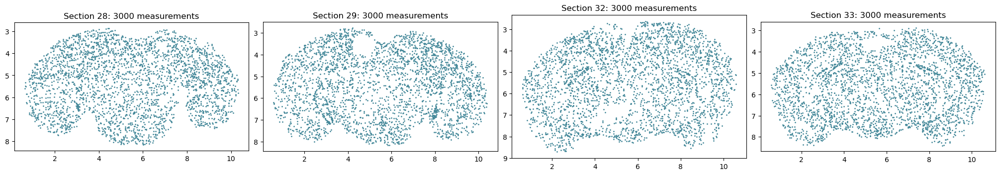

In [2]:
selected=[p for p in PAIRS if p[0]==PHASE]
sections=sorted({s for _,a,b in selected for s in (a,b)})
cohort=load_registration_sections(sections,maximum=MAXIMUM,seed=SEED)
display(cohort['inventory'])
cohort['inventory'].to_csv(OUTPUT/f'{PHASE}_inventory.csv',index=False)
for _,a,b in selected:
    gap=cohort['blocks'][b]['z']-cohort['blocks'][a]['z']
    if not np.isclose(gap,.2): raise ValueError(f'Unexpected section gap: {a}/{b}: {gap}')
fig,axes=plt.subplots(1,len(sections),figsize=(5*len(sections),5),squeeze=False,layout='constrained')
for ax,s in zip(axes.flat,sections):
    block=cohort['blocks'][s]
    ax.scatter(*block['xy'].T,s=1,color='#448899',rasterized=True)
    ax.set(title=f"Section {s}: {len(block['ids'])} measurements",aspect='equal')
    ax.invert_yaxis()
export(fig,PHASE+'_input_sections')


## Fit or load all methods

Enable the RUN flags above to start missing fits. Completed caches load regardless
of flags. There is no silent fallback on failure. Configuration/input/source changes
produce new caches. Exact per-method fits can be reused from earlier report archives.
The comparison includes geometry-only ICP, PASTE, CAST, and splat registration.
Splat non-affine refinement follows its affine fit.

Each perturbed case is fitted from its actual perturbed coordinates; the original
positions and the inverse transform are evaluation-only. Natural cross-section
alignment has no pointwise ground truth. The smooth control adds a bounded sinusoidal
x displacement after a 20-degree rotation and translation; no points are clipped.

Experiment names specify the actual direction and tissue:
- `25_to_24_cross_section_alignment`: section 25 mapped into section 24's frame.
- `24_same_section_rigid_recovery`: a rotated/translated copy of section 24 mapped
  back to its original coordinates. The imposed transform has no scale or shear.
- `24_same_section_smooth_recovery`: the same copy with additional sinusoidal
  displacement, mapped back to the original section 24 coordinates.

The other pairs follow the same naming convention. Method labels such as "Splat
affine" describe the fitted model, not the imposed distortion. "No additional
registration" retains the supplied coordinates (distorted coordinates in controls).
Legacy condition/cache keys are preserved internally to avoid retraining.


In [3]:
cases=[]
for role,a,b in selected:
    for condition in CONDITIONS:
        pair,evaluation=make_case(cohort,a,b,condition)
        name=f'{a}_to_{b}_{condition}'
        mappings={'Unregistered':pair['xy'][1].copy()}
        artifacts={};native=None
        for family in ['Geometry','PASTE','CAST','Splat']:
            print(case_title(name),family,flush=True)
            result,folder=cached_method(family,pair,OPTIONS[family],OUTPUT/name,FIGURES/name,
                                        run=RUN[family])
            artifacts[family]=(result,folder)
            if family in ['CAST','Splat']:
                mappings[family+' affine']=result['affine']
                mappings[family+' non-affine']=result['mapped']
            else:
                title={'Geometry':'Geometry rigid ICP','PASTE':'PASTE'}[family]
                mappings[title]=result['mapped']
            if family=='PASTE': native=result['native']
        cases.append(dict(name=name,pair=pair,evaluation=evaluation,mappings=mappings,
                          artifacts=artifacts,native=native,role=role))


Section 29 to section 28: cross-section alignment Geometry
Section 29 to section 28: cross-section alignment PASTE
Section 29 to section 28: cross-section alignment CAST
Section 29 to section 28: cross-section alignment Splat
Section 28: same-section rigid recovery Geometry
Section 28: same-section rigid recovery PASTE
Section 28: same-section rigid recovery CAST
Section 28: same-section rigid recovery Splat
Section 28: same-section smooth recovery Geometry
Section 28: same-section smooth recovery PASTE
Section 28: same-section smooth recovery CAST
Section 28: same-section smooth recovery Splat
Section 33 to section 32: cross-section alignment Geometry
Section 33 to section 32: cross-section alignment PASTE
Section 33 to section 32: cross-section alignment CAST
Section 33 to section 32: cross-section alignment Splat
Section 32: same-section rigid recovery Geometry
Section 32: same-section rigid recovery PASTE
Section 32: same-section rigid recovery CAST
Section 32: same-section rigid r

## Reconstruction fidelity before interpreting alignment

Cross-section fits are compared with a spatially constant mean profile. Ordinary
cosine, centered cosine, R2 over constant, and marker maps are in-sample descriptive
checks. High global cosine alone is insufficient. Marker color scales are shared
within each section; expression values are released log2 values, not raw counts.

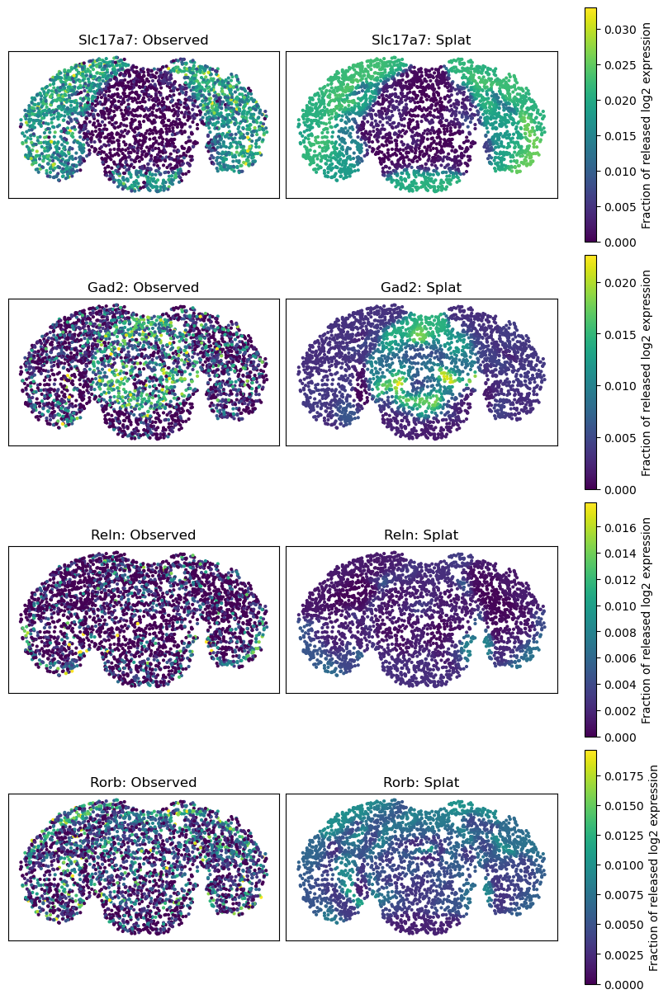

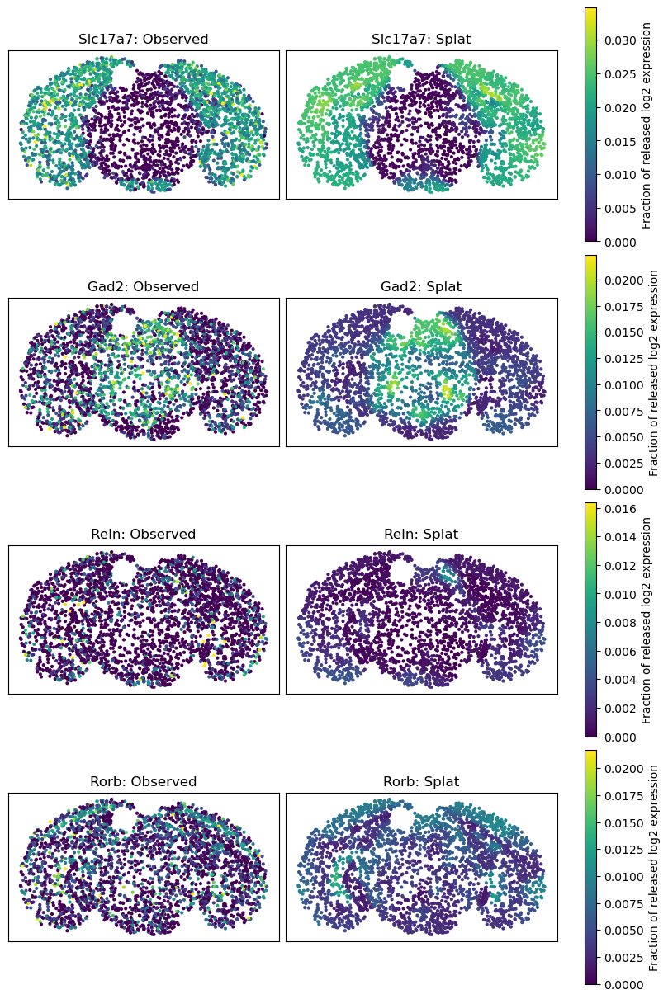

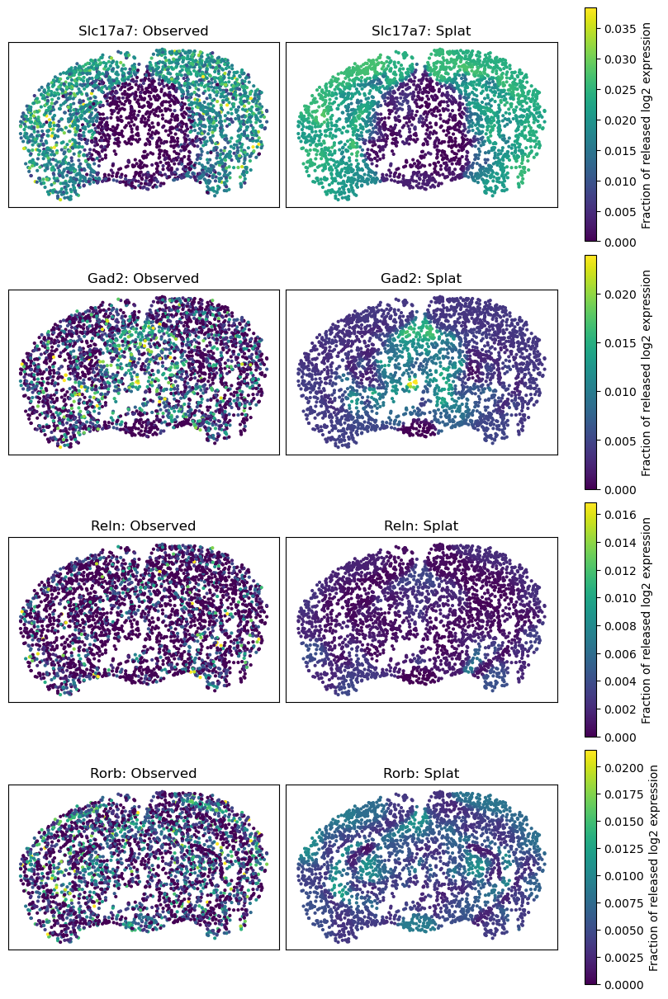

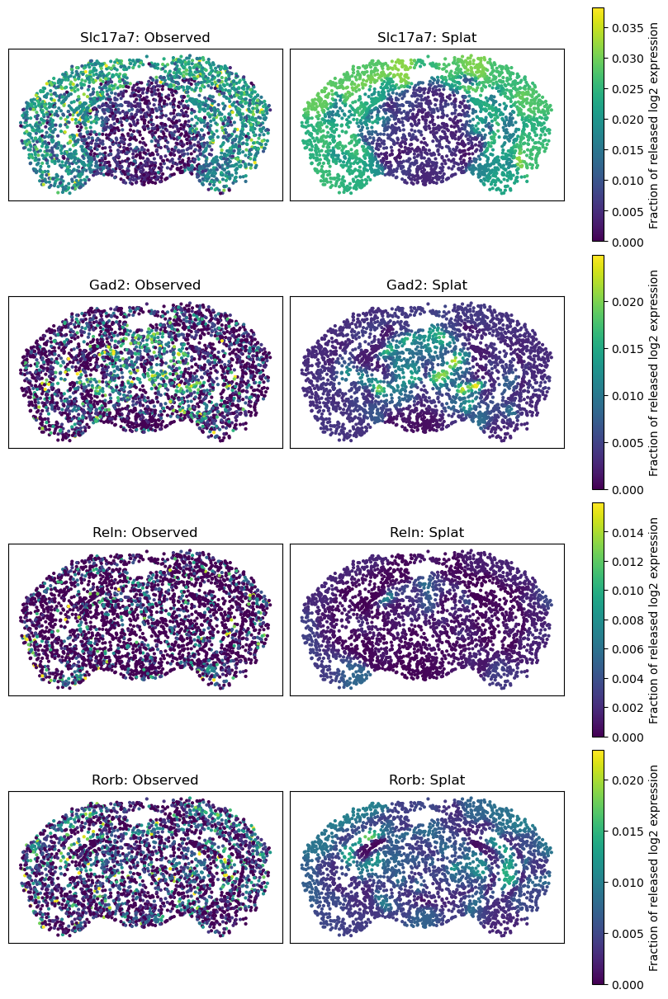

,section,method,parameters,profile_cosine,constant_profile_cosine,centered_cosine,centered_cosine_defined_fraction,r2_over_constant,profile_mae,constant_profile_mae
0,C57BL6J-638850.28,Splat,111783,0.7428,0.6706,0.4254,1,0.1357,0.001548,0.001934
1,C57BL6J-638850.29,Splat,111783,0.753,0.6716,0.4501,1,0.1568,0.001527,0.001951
2,C57BL6J-638850.32,Splat,111783,0.7421,0.6658,0.4232,1,0.1444,0.00157,0.001969
3,C57BL6J-638850.33,Splat,111783,0.729,0.6527,0.418,1,0.1272,0.001615,0.002021


In [4]:
recon=[];gene_tables=[]
MARKERS=['Slc17a7','Gad1','Gad2','Reln','Rorb','Mbp']
for case in cases:
    if case['evaluation']['condition']!='natural': continue
    pair=case['pair']
    splat_folder=case['artifacts']['Splat'][1]/'work'
    for i,section in enumerate((pair['reference'],pair['query'])):
        observed=pair['counts'][i].toarray()
        observed/=observed.sum(1,keepdims=True)
        models={}
        opts=SPLAT['engine_options']
        model=AmplitudeSplatField(**opts['splat_config'],num_genes=len(pair['genes']),init_log_amplitude=opts['init_log_amplitude']).to(DEVICE)
        model.load_state_dict(torch.load(splat_folder/f'field_{i}.pt',map_location=DEVICE,weights_only=True))
        models['Splat']=model
        markers=[g for g in MARKERS if g in pair['genes']]
        ids=[list(pair['genes']).index(g) for g in markers]
        maps={'Observed':observed[:,ids]}
        for method,model in models.items():
            model.eval().requires_grad_(False)
            predicted=np.empty_like(observed)
            with torch.no_grad():
                for start in range(0,len(observed),256):
                    rate=model(torch.tensor(pair['xy'][i][start:start+256],device=DEVICE,dtype=torch.float32)).exp().cpu().numpy()
                    if not np.isfinite(rate).all(): raise ValueError('Invalid field prediction')
                    predicted[start:start+256]=rate/np.maximum(rate.sum(1,keepdims=True),1e-12)
            summary,genes,_=profile_metrics(observed,predicted,observed.mean(0),pair['genes'])
            recon.append(dict(section=section,method=method,parameters=sum(p.numel() for p in model.parameters()),**summary))
            gene_tables.append(genes.assign(section=section,method=method))
            maps[method]=predicted[:,ids]
        if markers:
            fig,axes=plt.subplots(len(markers),2,figsize=(8,3*len(markers)),squeeze=False,layout='constrained')
            for j,gene in enumerate(markers):
                vmax=max(float(np.quantile(v[:,j],.995)) for v in maps.values())
                for ax,(method,values) in zip(axes[j],maps.items()):
                    im=ax.scatter(*pair['xy'][i].T,c=values[:,j],s=4,vmin=0,vmax=max(vmax,1e-8),rasterized=True)
                    ax.set(title=f'{gene}: {method}',aspect='equal',xticks=[],yticks=[]);ax.invert_yaxis()
                fig.colorbar(im,ax=list(axes[j]),label='Fraction of released log2 expression')
            export(fig,section+'_reconstruction')
        del models,model
recon=pd.DataFrame(recon);display(recon)
recon.to_csv(OUTPUT/f'{PHASE}_reconstruction.csv',index=False)
pd.concat(gene_tables,ignore_index=True).to_csv(OUTPUT/f'{PHASE}_gene_metrics.csv',index=False)


## Anatomical agreement, recovery, and geometry

Primary anatomical agreement uses the same uniform-marginal spatial transport for
every method, preserving the fitted coordinate frame. Alternative CCF agreement
uses independently centered/minimum-spacing-normalized coordinates for other methods
and native coupling for PASTE. This method-specific readout is not directly
interchangeable with the primary score. Coverage is plotted in both directions;
triangle reversals remain a diagnostic-table check.

Pointwise recovery error is defined only for same-section controls. Do not average
these controls together with natural cross-section results. Plots use atlas region
colors and show every method, without error-line overlays.

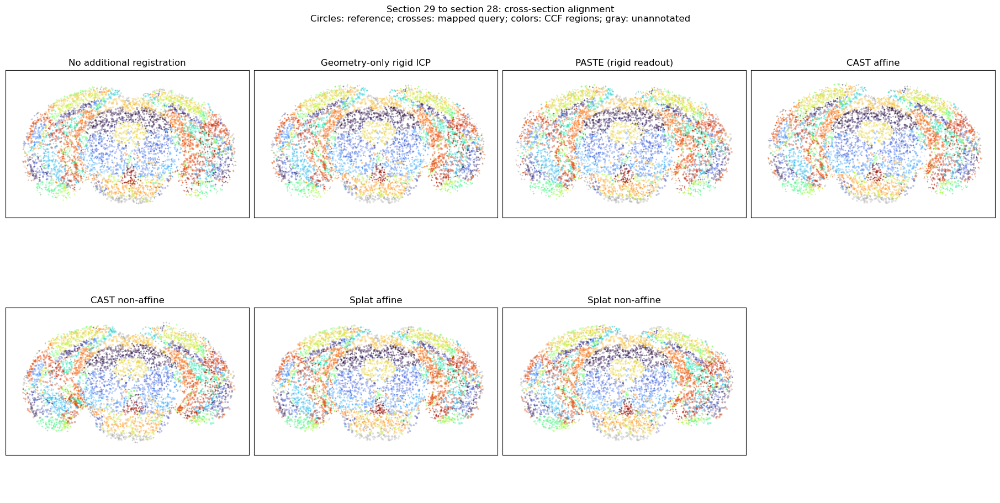

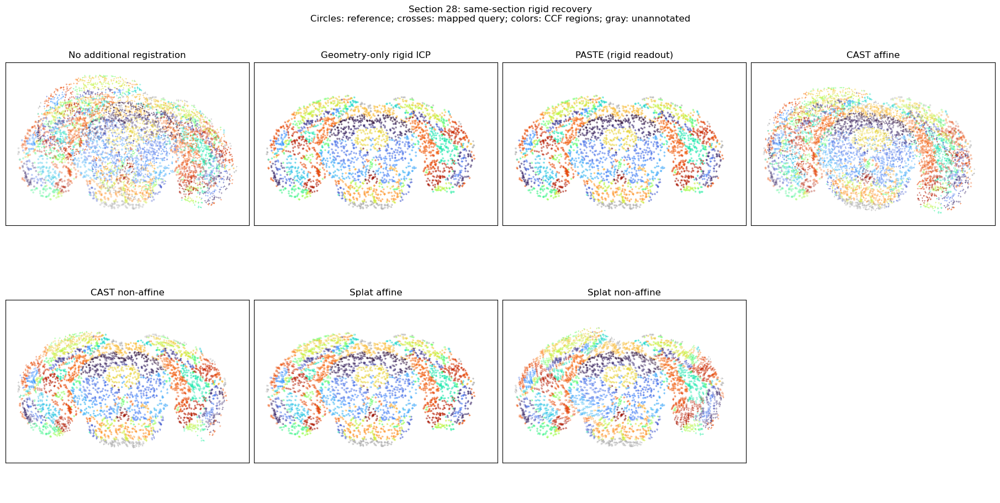

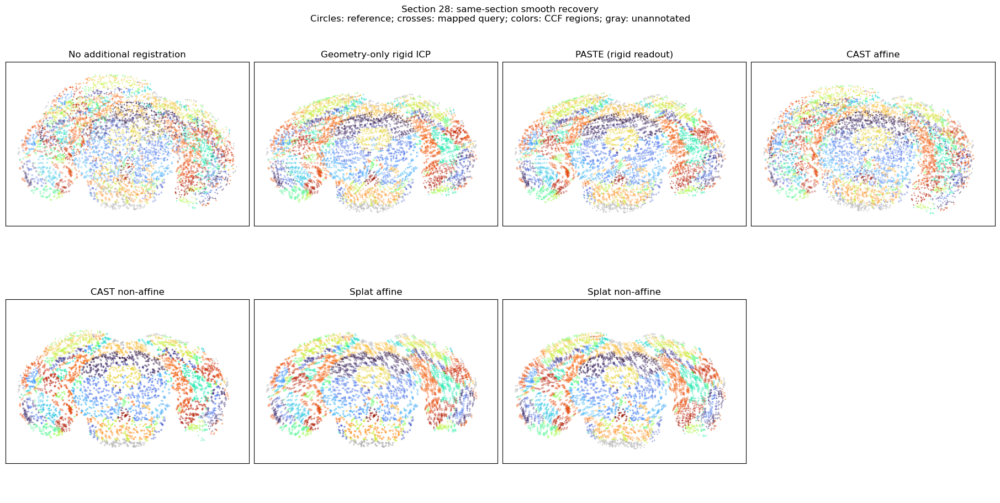

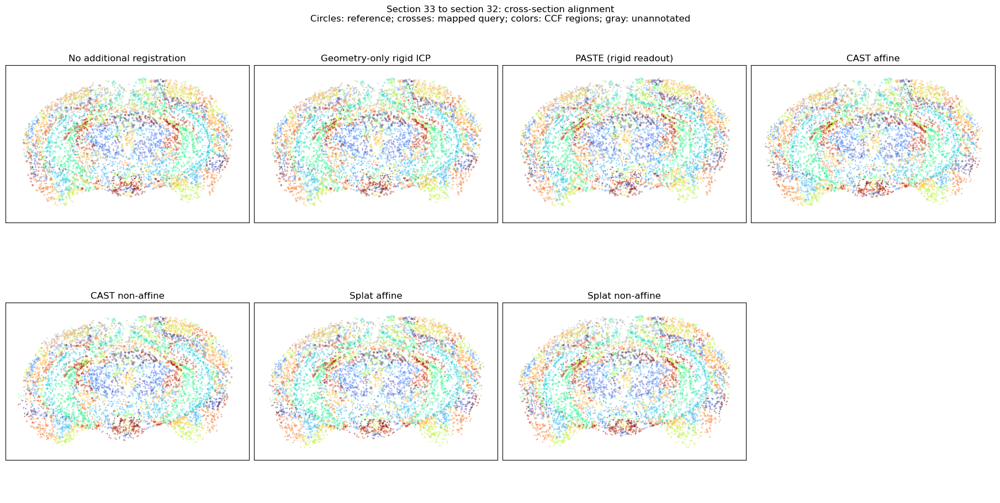

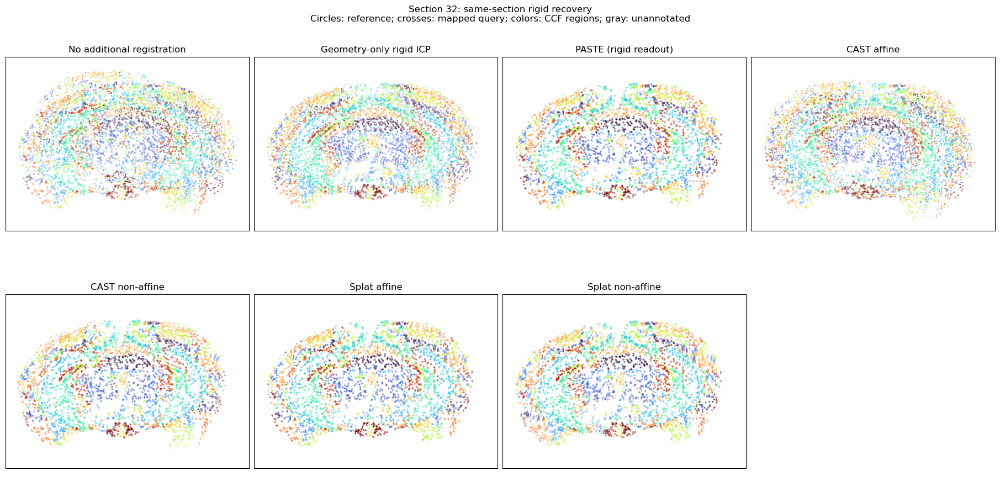

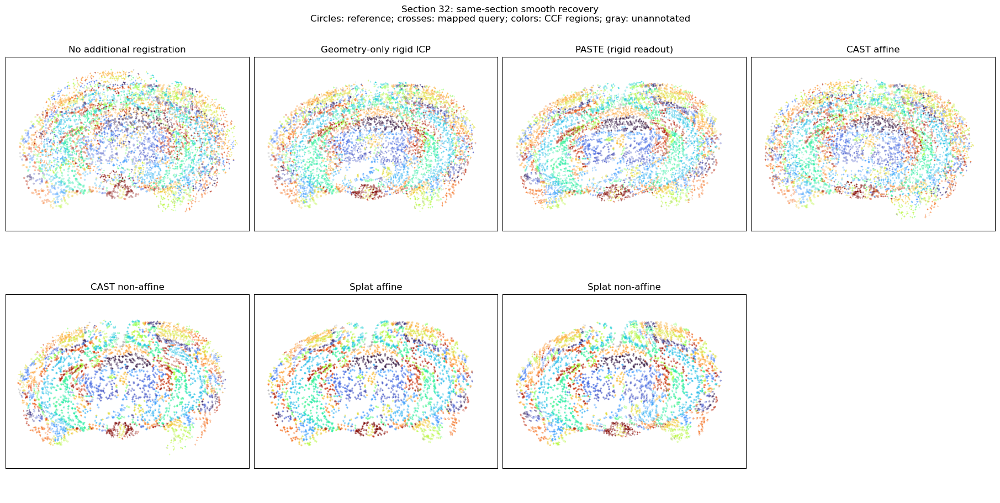

Cross-section alignment (no imposed distortion)


,Experiment,Method,Primary CCF agreement (fraction of total mass),Annotated-pair mass (fraction),CCF agreement within annotated pairs,Alternative CCF agreement (method-specific readout),Query near reference (fraction),Reference near query (fraction),Reversed triangles (fraction),Median recovery error (reference spacings),90th-percentile recovery error (reference spacings)
0,Section 29 to section 28: cross-section alignment,No additional registration,0.306,0.9463,0.3234,0.2967,0.8447,0.868,0,NaN,NaN
1,Section 29 to section 28: cross-section alignment,Geometry-only rigid ICP,0.336,0.945,0.3556,0.3143,0.845,0.8397,0,NaN,NaN
2,Section 29 to section 28: cross-section alignment,PASTE (rigid readout),0.2853,0.9433,0.3025,0.2993,0.8177,0.841,0,NaN,NaN
3,Section 29 to section 28: cross-section alignment,CAST affine,0.319,0.945,0.3376,0.2967,0.8333,0.8443,0,NaN,NaN
4,Section 29 to section 28: cross-section alignment,CAST non-affine,0.3367,0.9443,0.3565,0.1173,0.8617,0.8153,0.0006708,NaN,NaN
5,Section 29 to section 28: cross-section alignment,Splat affine,0.334,0.943,0.3542,0.3047,0.8927,0.8473,0,NaN,NaN
6,Section 29 to section 28: cross-section alignment,Splat non-affine,0.3187,0.9417,0.3384,0.2693,0.8657,0.832,0.0001677,NaN,NaN
21,Section 33 to section 32: cross-section alignment,No additional registration,0.1867,0.9,0.2074,0.16,0.871,0.845,0,NaN,NaN
22,Section 33 to section 32: cross-section alignment,Geometry-only rigid ICP,0.1863,0.9,0.207,0.164,0.871,0.846,0,NaN,NaN
23,Section 33 to section 32: cross-section alignment,PASTE (rigid readout),0.1753,0.899,0.195,0.1903,0.8563,0.8343,0,NaN,NaN


Same-section rigid recovery (rotation + translation)


,Experiment,Method,Primary CCF agreement (fraction of total mass),Annotated-pair mass (fraction),CCF agreement within annotated pairs,Alternative CCF agreement (method-specific readout),Query near reference (fraction),Reference near query (fraction),Reversed triangles (fraction),Median recovery error (reference spacings),90th-percentile recovery error (reference spacings)
7,Section 28: same-section rigid recovery,No additional registration,0.136,0.9317,0.146,0.225,0.7113,0.726,0,23.63,39.04
8,Section 28: same-section rigid recovery,Geometry-only rigid ICP,0.9643,0.9643,1,0.9643,1,1,0,5.986e-13,7.407e-13
9,Section 28: same-section rigid recovery,PASTE (rigid readout),0.9643,0.9643,1,0.9643,1,1,0,2.866e-13,3.254e-13
10,Section 28: same-section rigid recovery,CAST affine,0.253,0.9393,0.2693,0.2767,0.7823,0.802,0,15.05,22.66
11,Section 28: same-section rigid recovery,CAST non-affine,0.9603,0.9643,0.9959,0.8263,0.974,0.988,0.0003353,0.417,1.649
12,Section 28: same-section rigid recovery,Splat affine,0.9643,0.9643,1,0.9643,1,1,0,0.3543,0.5945
13,Section 28: same-section rigid recovery,Splat non-affine,0.961,0.9643,0.9965,0.963,0.976,0.9913,0.0001677,0.7056,1.834
28,Section 32: same-section rigid recovery,No additional registration,0.08867,0.9837,0.09014,0.1687,0.7227,0.7313,0,24.11,36.66
29,Section 32: same-section rigid recovery,Geometry-only rigid ICP,0.4557,0.9847,0.4628,0.4813,0.887,0.879,0,5.839,7.93
30,Section 32: same-section rigid recovery,PASTE (rigid readout),0.9917,0.9917,1,0.9917,1,1,0,2.864e-13,3.163e-13


Same-section smooth recovery (rigid + sinusoidal displacement)


,Experiment,Method,Primary CCF agreement (fraction of total mass),Annotated-pair mass (fraction),CCF agreement within annotated pairs,Alternative CCF agreement (method-specific readout),Query near reference (fraction),Reference near query (fraction),Reversed triangles (fraction),Median recovery error (reference spacings),90th-percentile recovery error (reference spacings)
14,Section 28: same-section smooth recovery,No additional registration,0.1237,0.9323,0.1326,0.182,0.7097,0.7217,0,26.05,43.55
15,Section 28: same-section smooth recovery,Geometry-only rigid ICP,0.658,0.951,0.6919,0.6353,0.9153,0.9063,0,3.617,6.832
16,Section 28: same-section smooth recovery,PASTE (rigid readout),0.658,0.9543,0.6895,0.6903,0.9177,0.9033,0,3.361,6.132
17,Section 28: same-section smooth recovery,CAST affine,0.2153,0.9373,0.2297,0.2283,0.7643,0.7993,0,17.63,24.9
18,Section 28: same-section smooth recovery,CAST non-affine,0.9553,0.9637,0.9914,0.8013,0.9753,0.9877,0.0006707,0.5073,1.679
19,Section 28: same-section smooth recovery,Splat affine,0.9637,0.9643,0.9993,0.9643,1,1,0,0.9836,1.557
20,Section 28: same-section smooth recovery,Splat non-affine,0.9537,0.964,0.9893,0.9557,0.977,0.9797,0,1.2,2.06
35,Section 32: same-section smooth recovery,No additional registration,0.07667,0.9833,0.07797,0.1263,0.722,0.7387,0,26.61,40.96
36,Section 32: same-section smooth recovery,Geometry-only rigid ICP,0.32,0.984,0.3252,0.3247,0.8537,0.855,0,8.73,15.15
37,Section 32: same-section smooth recovery,PASTE (rigid readout),0.5117,0.986,0.5189,0.5313,0.8923,0.8967,0,4.068,7.223


In [5]:
metrics=[];regions=[]
for case in cases:
    table,per_region=score_case(case['pair'],case['evaluation'],case['mappings'],case['native'])
    condition=case['evaluation']['condition']
    metrics.append(table.assign(case=case_label(case['name']),condition=condition,role=case['role']))
    regions.append(per_region.assign(case=case_label(case['name']),condition=condition))
    labels=case['evaluation']['labels']
    categories=np.unique(np.concatenate([x[np.isfinite(x)] for x in labels]))
    colors={v:plt.get_cmap('turbo')(i/max(1,len(categories)-1)) for i,v in enumerate(categories)}
    positions=np.vstack([case['pair']['xy'][0],*case['mappings'].values()])
    lo,hi=positions.min(0)-.03,positions.max(0)+.03
    fig,axes=plt.subplots(2,4,figsize=(18,9),layout='constrained')
    for ax,(method,mapped) in zip(axes.flat,case['mappings'].items()):
        for xy,lab,marker,alpha in [(case['pair']['xy'][0],labels[0],'o',.3),(mapped,labels[1],'+',.8)]:
            ax.scatter(*xy.T,c=[colors.get(v,'#aaaaaa') for v in lab],s=5,marker=marker,alpha=alpha,linewidths=.4,rasterized=True)
        ax.set(title=method_label(method),xlim=(lo[0],hi[0]),ylim=(hi[1],lo[1]),aspect='equal',xticks=[],yticks=[])
    for ax in axes.flat[len(case['mappings']):]: ax.axis('off')
    fig.suptitle(case_title(case['name'])+'\nCircles: reference; crosses: mapped query; colors: CCF regions; gray: unannotated')
    export(fig,case_label(case['name'])+'_registration')
metrics=pd.concat(metrics,ignore_index=True)
metrics.to_csv(OUTPUT/f'{PHASE}_registration_metrics.csv',index=False)
pd.concat(regions,ignore_index=True).to_csv(OUTPUT/f'{PHASE}_region_recall.csv',index=False)
for condition,group in metrics.groupby('condition',sort=False):
    print(condition_label(condition))
    display(display_metrics(group[['case','method','matching_mass','scored_mass','agreement_given_scored',
        'historical_agreement','query_coverage_2_spacings','reference_coverage_2_spacings',
        'local_fold_fraction','median_recovery_error_spacings','p90_recovery_error_spacings']]))


## Quantitative result figures

This section reads completed CSV results only. Run the setup cell and this section
to regenerate figures without loading data, fitting models, or rescoring transport.
Figures are exported to the same root figures directory as the spatial overlays.

- Agreement plots show each pair and condition separately. Dashed lines mark the
  no-additional-registration baseline. Primary CCF agreement includes unannotated
  transport mass in its denominator. Alternative CCF agreement uses a method-specific
  readout (native PASTE versus normalized spatial OT); it is not an equivalent accuracy measure.
- Coverage is shown in both directions. Triangle-reversal values remain in the
  diagnostic table rather than the figures.
- Recovery plots are only for known-transform controls. Circles and crosses mark
  median and 90th-percentile errors, not confidence intervals. The hybrid axis retains
  near-zero errors while showing large failures; numerical labels report both values.
- Reconstruction plots include the constant-profile cosine control and zero-R2
  reference. All reconstruction results are in-sample.

No error bars or pooled averages are shown: these runs do not provide independent
replicates for uncertainty estimation.

/home/javeda/Documents/Research/spatsplat/paper/allen_registration_plots.py:116: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), layout='constrained')


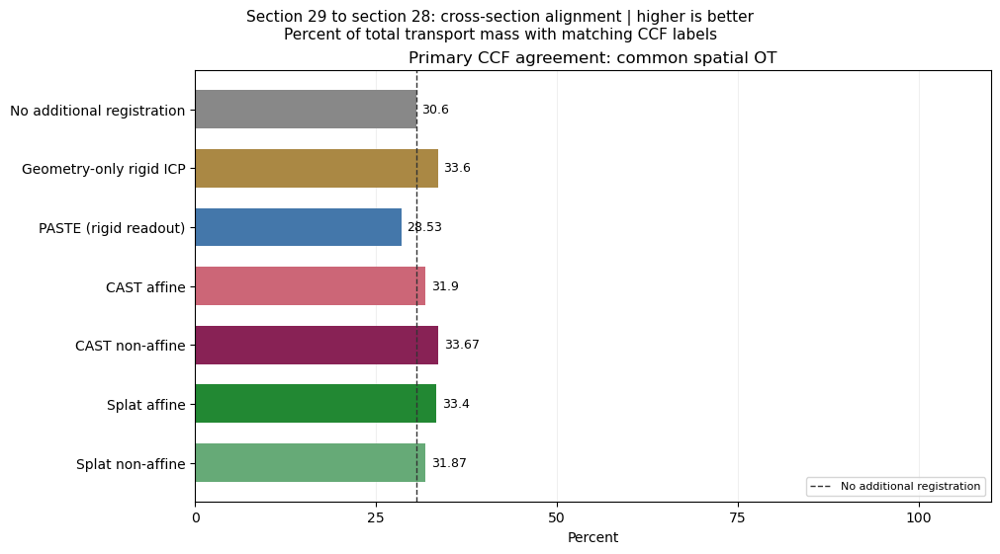

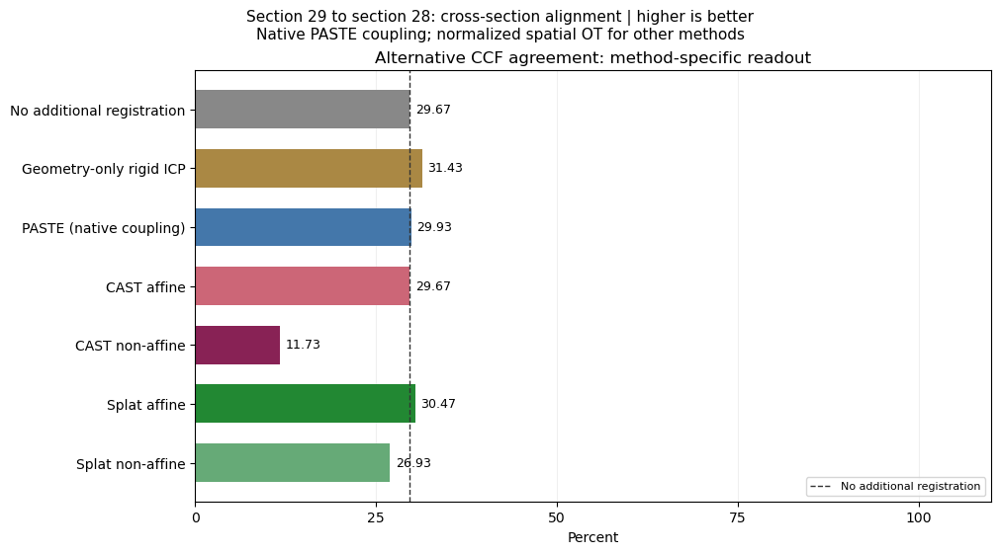

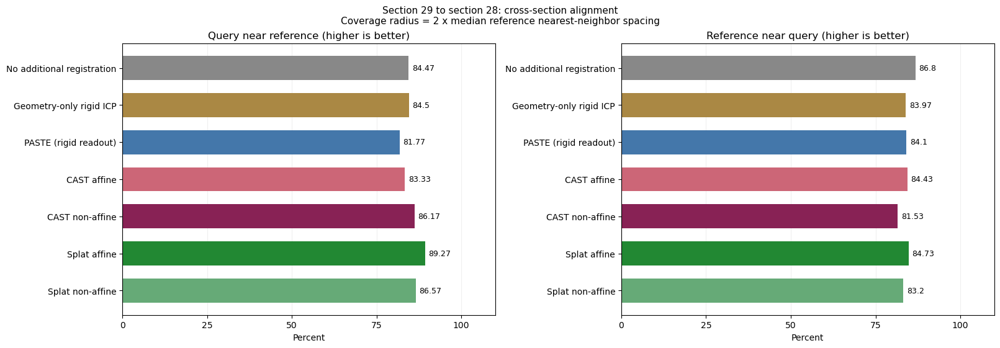

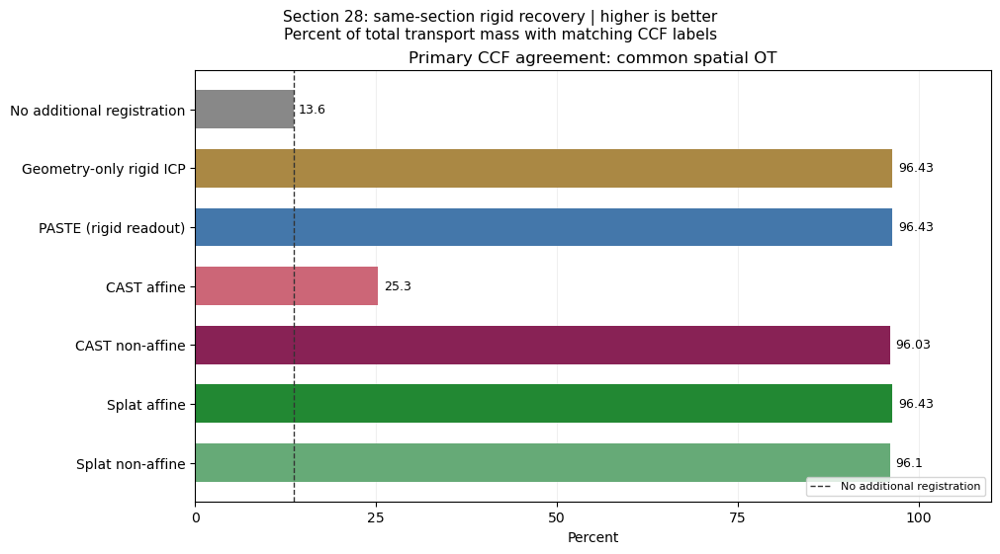

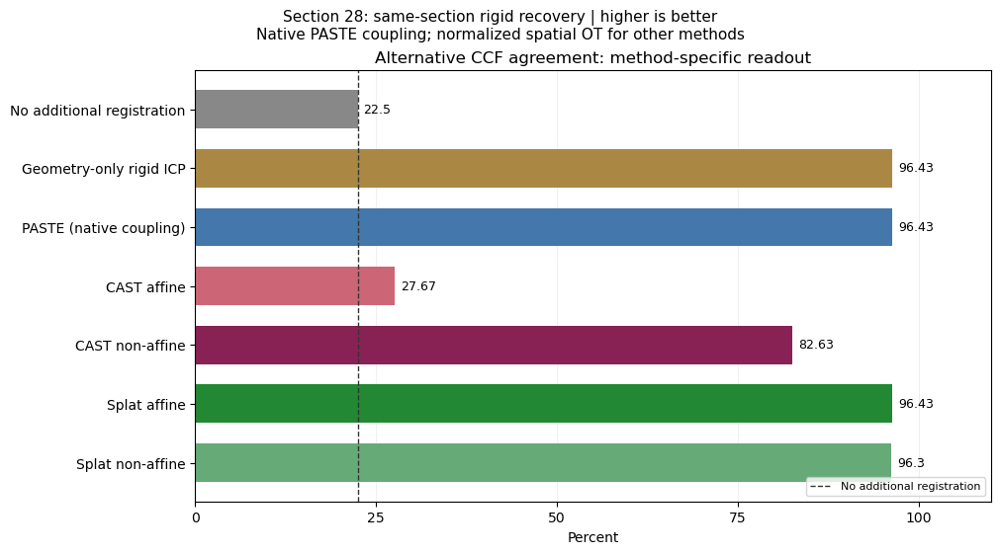

...

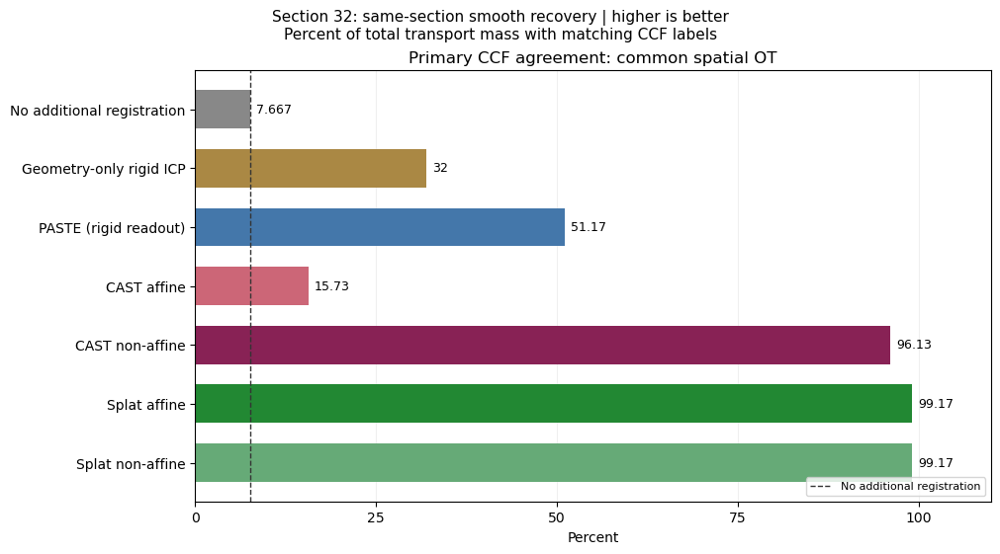

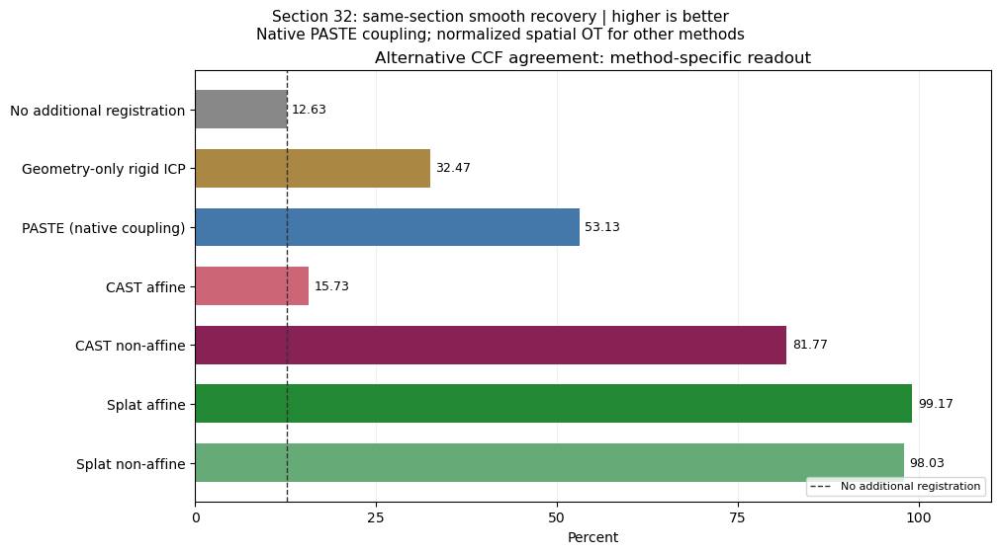

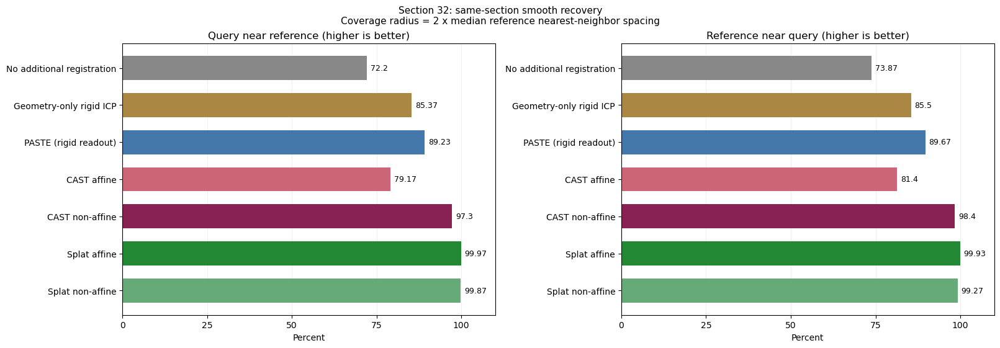

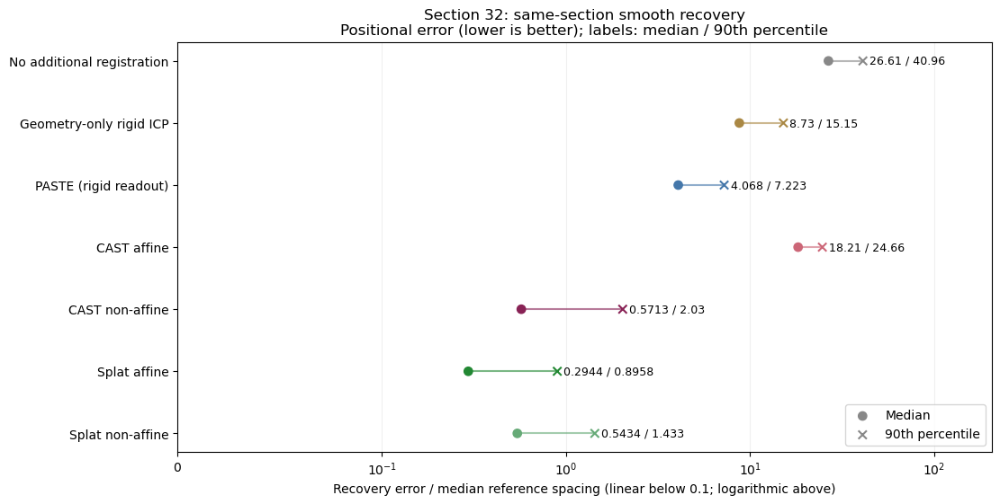

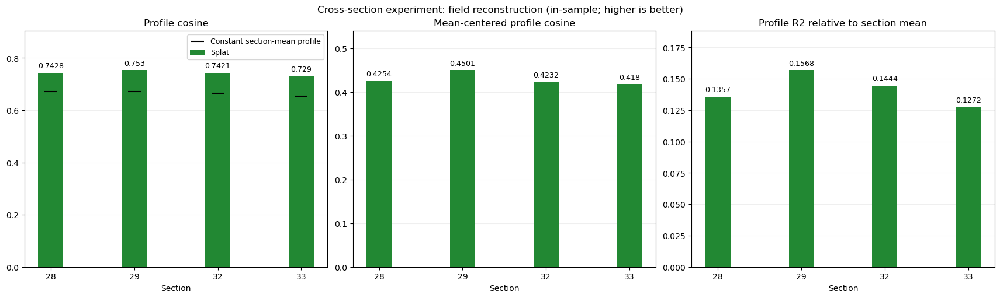

In [6]:
import importlib
import paper.allen_registration_plots as registration_plots
importlib.reload(registration_plots)
from paper.allen_registration_plots import registration_figures, reconstruction_figure

plot_metrics_path = OUTPUT / f'{PHASE}_registration_metrics.csv'
plot_reconstruction_path = OUTPUT / f'{PHASE}_reconstruction.csv'
for path in (plot_metrics_path, plot_reconstruction_path):
    if not path.exists():
        raise FileNotFoundError(f'Complete the analysis first: {path}')
plot_metrics = pd.read_csv(plot_metrics_path)
plot_reconstruction = pd.read_csv(plot_reconstruction_path)
quantitative_figures = registration_figures(plot_metrics, methods=METHOD_ORDER)
quantitative_figures[f'{PHASE}_reconstruction_metrics'] = reconstruction_figure(plot_reconstruction, methods=('Splat',))
for name, fig in quantitative_figures.items():
    export(fig, name)
    plt.close(fig)


## Post-registration expression cosine

Compare observed expression, not predicted fields, after registration. For each
query measurement, average up to five reference profiles within a fixed radius
using inverse-distance weights and compute cosine against the observed query
profile. Repeat in the opposite direction and average the two directional scores.
The radius is twice the median reference nearest-neighbor spacing, fixed across
methods. Profiles are fractions of released log2 expression, not raw counts.

The left panel averages only supported measurements; the right assigns zero to
unsupported measurements. Labels report symmetric coverage. An undefined supported
score is N/A, not zero. The dashed line marks no additional registration.

The gray control permutes source expression over coordinates 99 times, preserving
each method's neighbor assignments, averaging weights and support. Its mean and
5th-95th percentiles quantify the geometry-matched shuffled baseline; these are
not confidence intervals across biological replicates. Different methods can
have different shuffled baselines because their neighborhood geometry differs.

This is an in-sample expression-consistency metric: expression was also used for
registration. Same-section recovery uses identical source expression, making it
optimistic; do not pool it with natural cross-section alignment.

On first use, run setup, data loading and the fit/load cell to populate `cases`.
Completed model caches load without retraining. Then run this section; it performs
only expression scoring and plotting. Subsequent plots can load its saved score
table with just setup and this section.

,Experiment,Method,Supported cosine,Symmetric coverage,Coverage-weighted cosine,Shuffled supported cosine,Shuffled coverage-weighted cosine,Coverage-weighted gain over shuffle
0,Section 29 to section 28: cross-section alignment,No additional registration,0.6053,0.8563,0.5183,0.5219,0.4469,0.07138
1,Section 29 to section 28: cross-section alignment,Geometry-only rigid ICP,0.6007,0.8423,0.506,0.5198,0.4379,0.06809
2,Section 29 to section 28: cross-section alignment,PASTE (rigid readout),0.5808,0.8293,0.4817,0.5201,0.4313,0.05031
3,Section 29 to section 28: cross-section alignment,CAST affine,0.6,0.8388,0.5033,0.5194,0.4357,0.06761
4,Section 29 to section 28: cross-section alignment,CAST non-affine,0.6252,0.8385,0.5242,0.5213,0.4371,0.08707
5,Section 29 to section 28: cross-section alignment,Splat affine,0.6199,0.87,0.5393,0.5244,0.4562,0.08305
6,Section 29 to section 28: cross-section alignment,Splat non-affine,0.6211,0.8488,0.5272,0.5231,0.444,0.0832
7,Section 28: same-section rigid recovery,No additional registration,0.5516,0.7187,0.3964,0.5232,0.376,0.02038
8,Section 28: same-section rigid recovery,Geometry-only rigid ICP,1,1,1,0.4507,0.4507,0.5493
9,Section 28: same-section rigid recovery,PASTE (rigid readout),1,1,1,0.4507,0.4507,0.5493


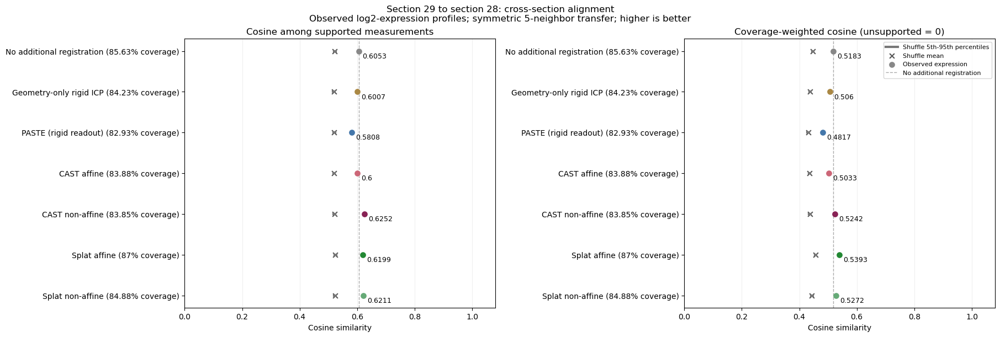

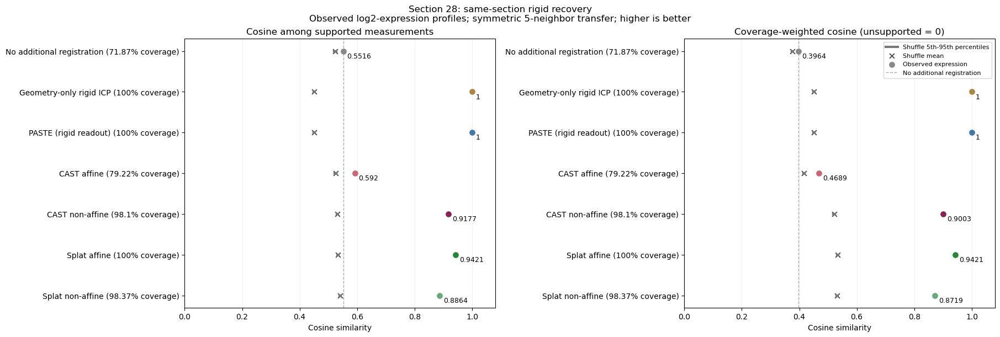

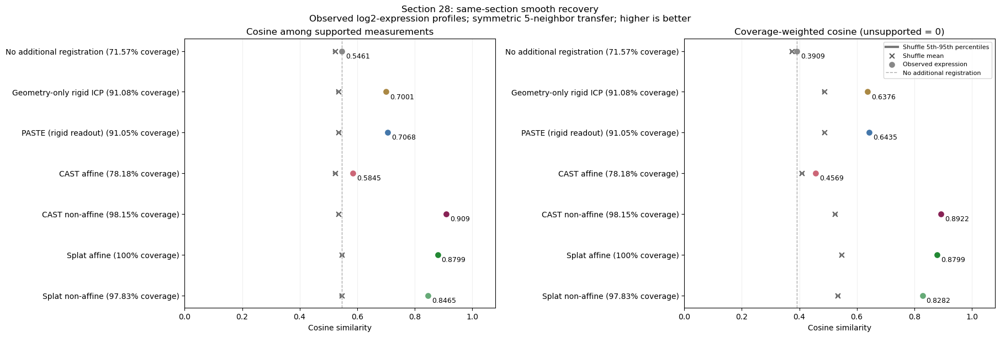

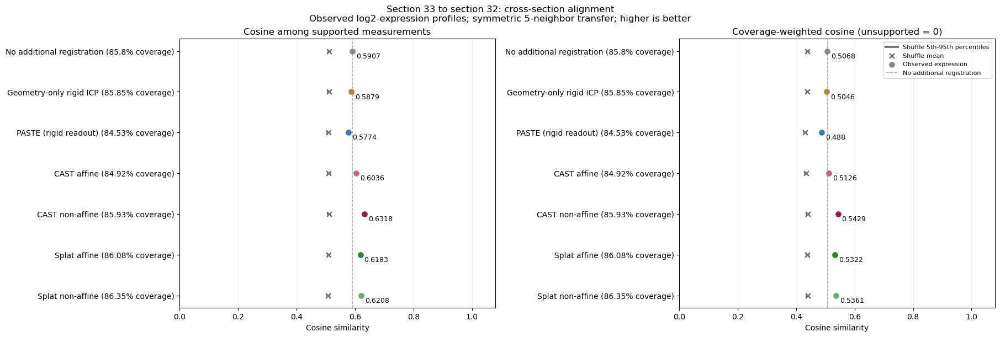

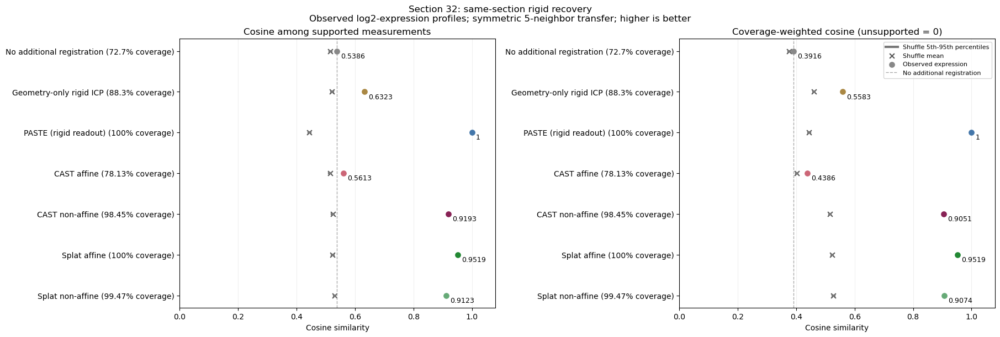

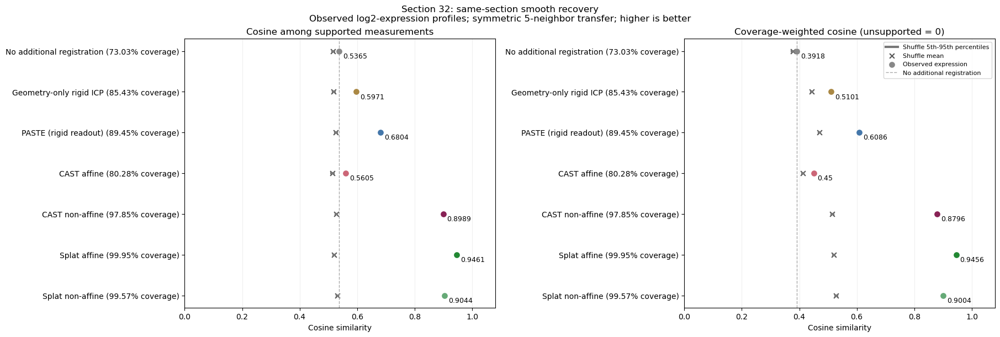

In [7]:
import importlib
import paper.allen_registration_cosine as cosine_analysis
importlib.reload(cosine_analysis)

COSINE_NEIGHBORS = 5
COSINE_PERMUTATIONS = 99
cosine_table_path = OUTPUT / f'{PHASE}_expression_cosine_k{COSINE_NEIGHBORS}_p{COSINE_PERMUTATIONS}_seed{SEED}.csv'
if 'cases' in globals() and cases and all(c['role'] == PHASE for c in cases):
    cosine_scores = cosine_analysis.cached_scores(cases, OUTPUT/'expression_cosine',
        k=COSINE_NEIGHBORS, permutations=COSINE_PERMUTATIONS, seed=SEED)
    cosine_scores.to_csv(cosine_table_path, index=False)
elif cosine_table_path.exists():
    cosine_scores = pd.read_csv(cosine_table_path)
else:
    raise RuntimeError('Load the completed case mappings using the fit/load cell first; no new model fitting is needed when caches exist.')

cosine_scores = cosine_scores[cosine_scores.method.isin(METHOD_ORDER)].copy()
cosine_display = cosine_scores[['case','method','profile_cosine','coverage',
    'coverage_weighted_cosine','profile_cosine_shuffle_mean',
    'coverage_weighted_cosine_shuffle_mean','coverage_weighted_cosine_gain_over_shuffle']].copy()
cosine_display['case'] = cosine_display['case'].map(case_title)
cosine_display['method'] = cosine_display['method'].map(method_label)
display(cosine_display.rename(columns={
    'case':'Experiment', 'method':'Method', 'profile_cosine':'Supported cosine',
    'coverage':'Symmetric coverage', 'coverage_weighted_cosine':'Coverage-weighted cosine',
    'profile_cosine_shuffle_mean':'Shuffled supported cosine',
    'coverage_weighted_cosine_shuffle_mean':'Shuffled coverage-weighted cosine',
    'coverage_weighted_cosine_gain_over_shuffle':'Coverage-weighted gain over shuffle'}))
for name, fig in cosine_analysis.cosine_figures(cosine_scores, methods=METHOD_ORDER).items():
    export(fig, name)
    plt.close(fig)


## Why can visual overlap exceed exact CCF agreement?

This evaluation-only analysis uses the fixed **primary spatial-transport coupling**
for every hierarchy level. Exact parcellation IDs are compared with Allen's predefined
**structure** and **division** groupings. No clusters are learned and no grouping is
chosen based on method performance. Higher coarse agreement is partly inevitable
when labels are merged; it is not evidence that registration improved.

The first figure shows percentage-point differences from Splat affine, with one
row per method to avoid overlapping lines. Positive values mean higher agreement.
Each hierarchy panel has its own symmetric axis range. The original absolute
agreement plot follows for context. Differences are not log ratios or percent
changes; no pseudocount is needed when agreement is zero.

The summary reports total matching mass, annotated-pair mass, agreement conditional
on annotation, and a marginal-label ceiling: the maximum matching mass allowed by
the two region-proportion distributions, ignoring geometry. That ceiling helps
identify limitations from different regional proportions; it is not a score target.

Region-recall heatmaps show matching mass divided by reference-region mass for every
method. Confusion matrices have reference regions as rows and query regions as
columns. Rows include transport to unannotated measurements in their denominators.
The largest 20 reference regions are selected by reference mass, not performance.
Only those named regions are displayed on both axes; other query regions and
unannotated measurements are hidden, not removed from the normalization.
Displayed rows may therefore sum to less than one. Full, untruncated matrices
including unannotated mass are exported as CSVs; agreement metrics are unchanged.

By default, natural cross-section cases are analyzed. Confusion plots show no
additional registration and the two splat methods; set CONFUSION_METHODS=METHOD_ORDER
to display every method. All methods are scored and their complete matrices saved
regardless. The fine-region labels include atlas acronyms where available.

Run setup, data loading and the fit/load cell first to populate cases. This section
does not fit models. Its first run computes spatial transport and downloads the small
official CCF hierarchy table into the existing ABC Atlas data cache if absent.
Correspondence caches and tables are separate from fitting artifacts.

/home/javeda/miniconda3/envs/spatsplat/lib/python3.11/site-packages/abc_atlas_access/abc_atlas_cache/cloud_cache.py:679: OutdatedManifestWarning: You are loading releases/20260415/manifest.json. A more up to date version of the dataset -- releases/20261031/manifest.json -- exists online. To see the changes between the two versions of the dataset, run
type.compare_manifests('releases/20260415/manifest.json', 'releases/20261031/manifest.json')
To load another version of the dataset, run
type.load_manifest('releases/20261031/manifest.json')
  warnings.warn(msg, OutdatedManifestWarning)


,Experiment,Method,Atlas level,Matching mass (fraction),Annotated-pair mass (fraction),Agreement within annotated pairs,Region-proportion ceiling,Reference unannotated mass,Query unannotated mass
0,Section 29 to section 28: cross-section alignment,No additional registration,parcellation,0.306,0.9463,0.3234,0.7243,0.03567,0.03167
1,Section 29 to section 28: cross-section alignment,No additional registration,structure,0.46,0.9463,0.4861,0.744,0.03567,0.03167
2,Section 29 to section 28: cross-section alignment,No additional registration,division,0.7277,0.9463,0.7689,0.8897,0.03567,0.03167
3,Section 29 to section 28: cross-section alignment,Geometry-only rigid ICP,parcellation,0.336,0.945,0.3556,0.7243,0.03567,0.03167
4,Section 29 to section 28: cross-section alignment,Geometry-only rigid ICP,structure,0.4863,0.945,0.5146,0.744,0.03567,0.03167
5,Section 29 to section 28: cross-section alignment,Geometry-only rigid ICP,division,0.7303,0.945,0.7728,0.8897,0.03567,0.03167
6,Section 29 to section 28: cross-section alignment,PASTE (rigid readout),parcellation,0.2853,0.9433,0.3025,0.7243,0.03567,0.03167
7,Section 29 to section 28: cross-section alignment,PASTE (rigid readout),structure,0.452,0.9433,0.4792,0.744,0.03567,0.03167
8,Section 29 to section 28: cross-section alignment,PASTE (rigid readout),division,0.7187,0.9433,0.7618,0.8897,0.03567,0.03167
9,Section 29 to section 28: cross-section alignment,CAST affine,parcellation,0.319,0.945,0.3376,0.7243,0.03567,0.03167


/home/javeda/Documents/Research/spatsplat/paper/allen_ccf_diagnostics.py:177: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(13, max(5, .32*len(selected)+2)), layout='constrained')


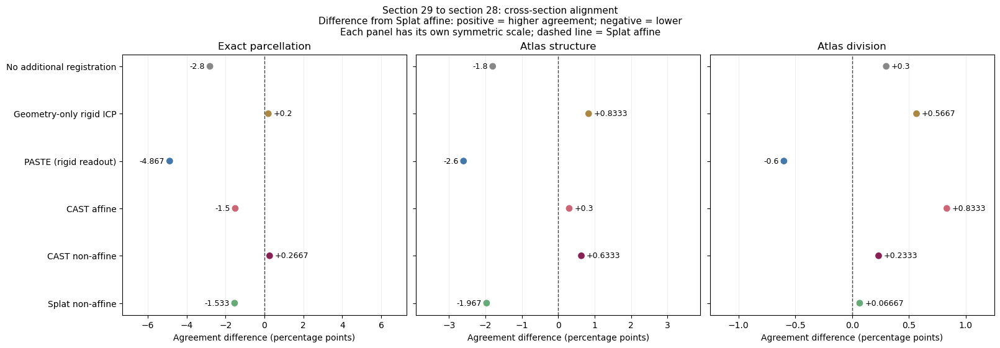

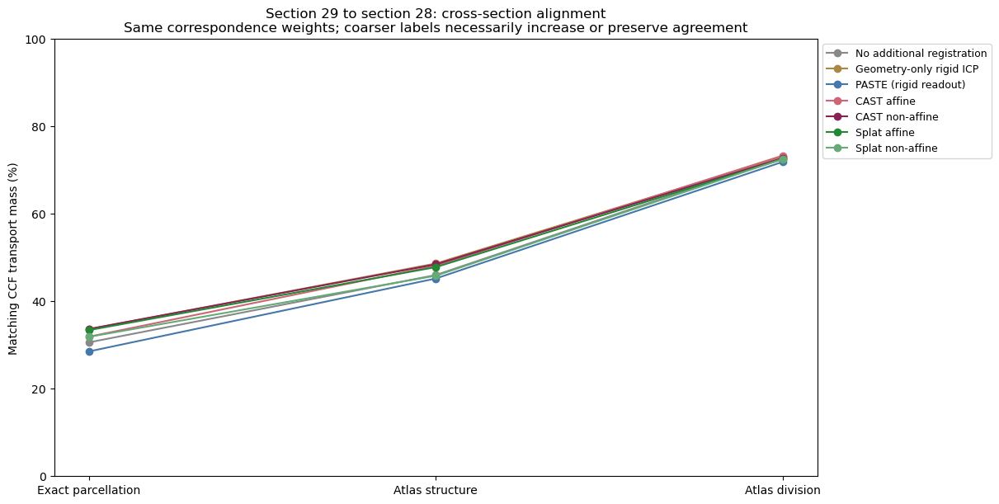

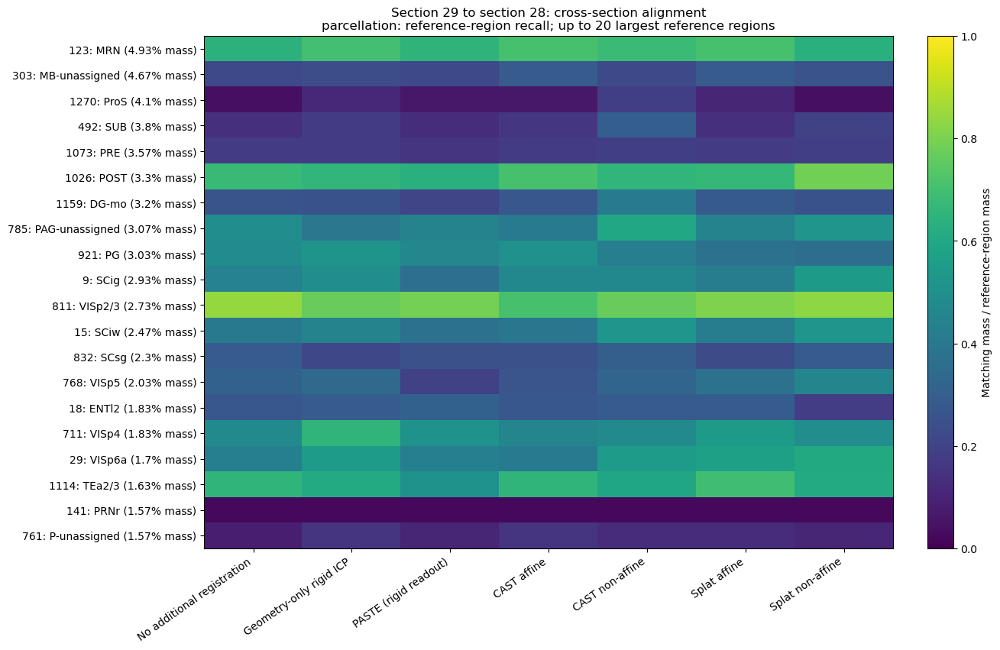

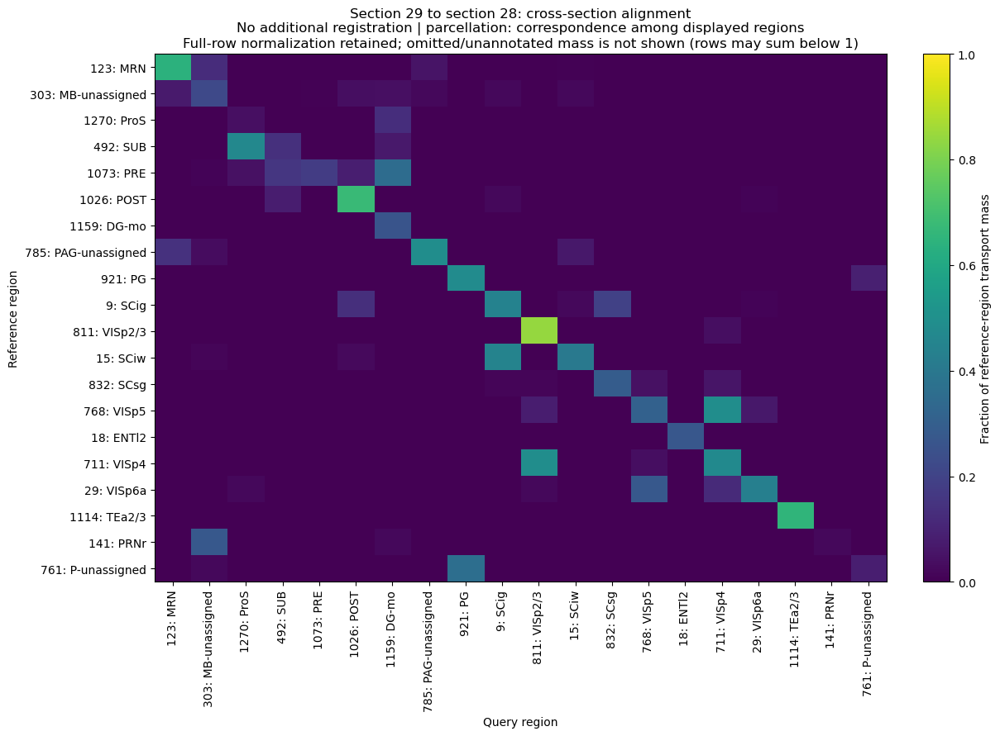

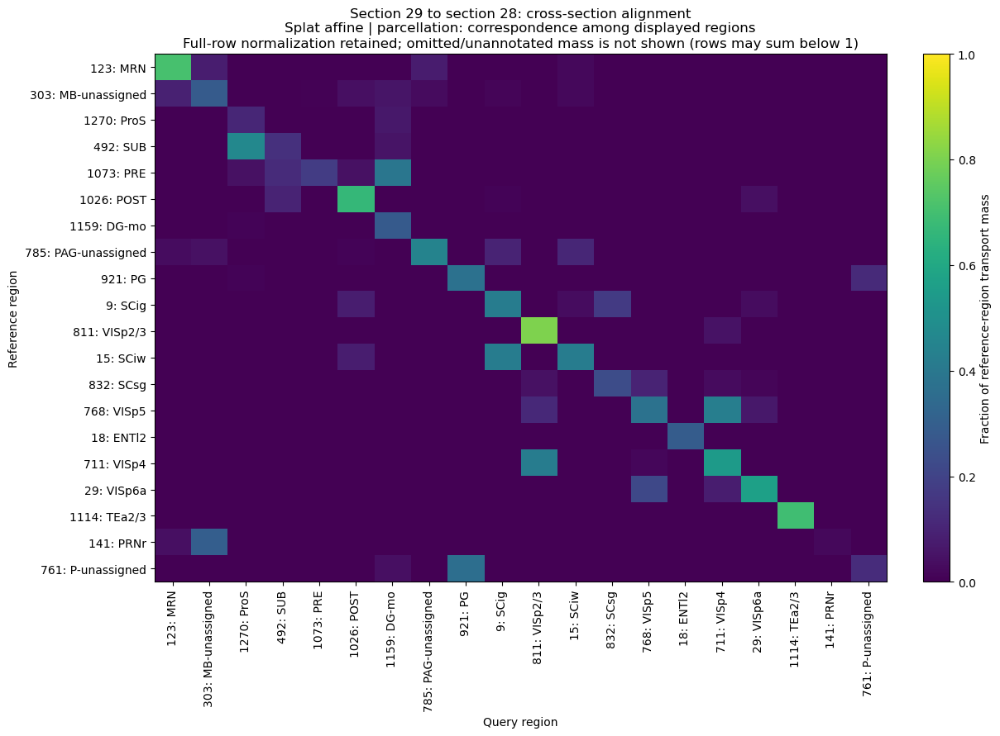

...

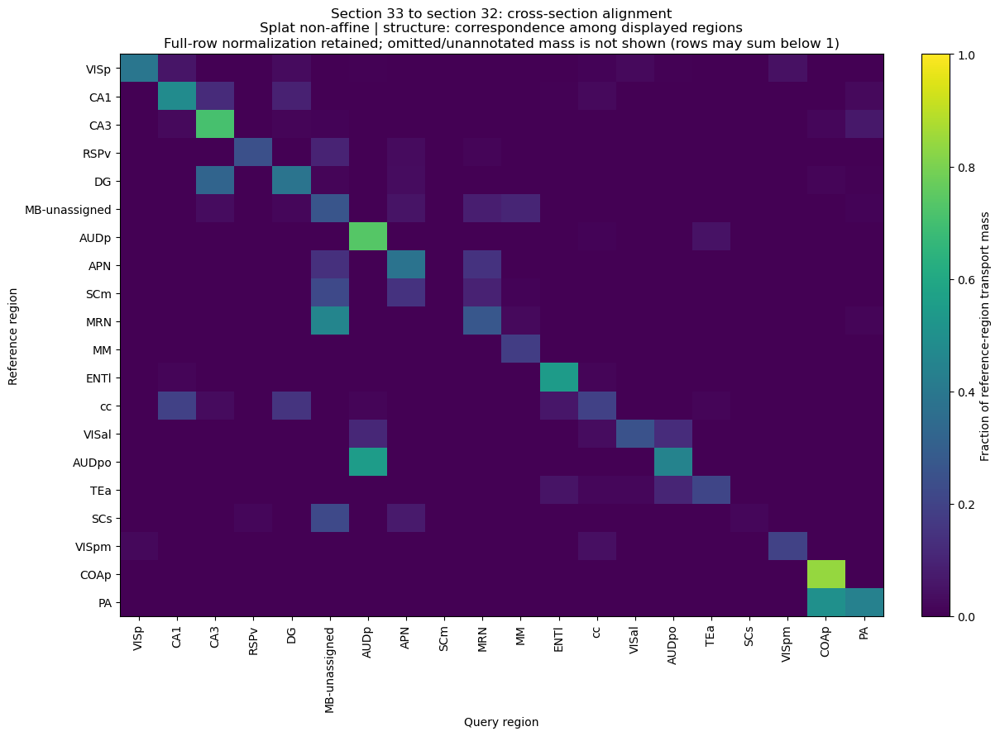

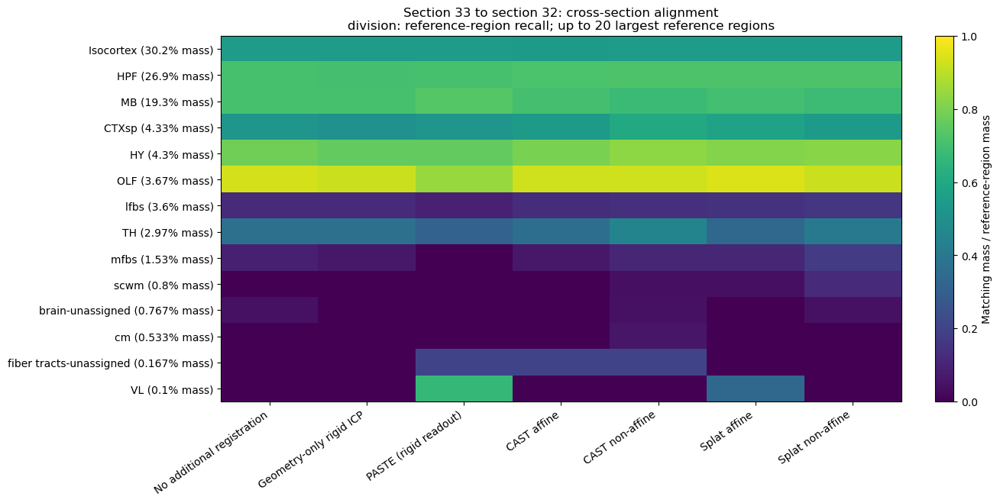

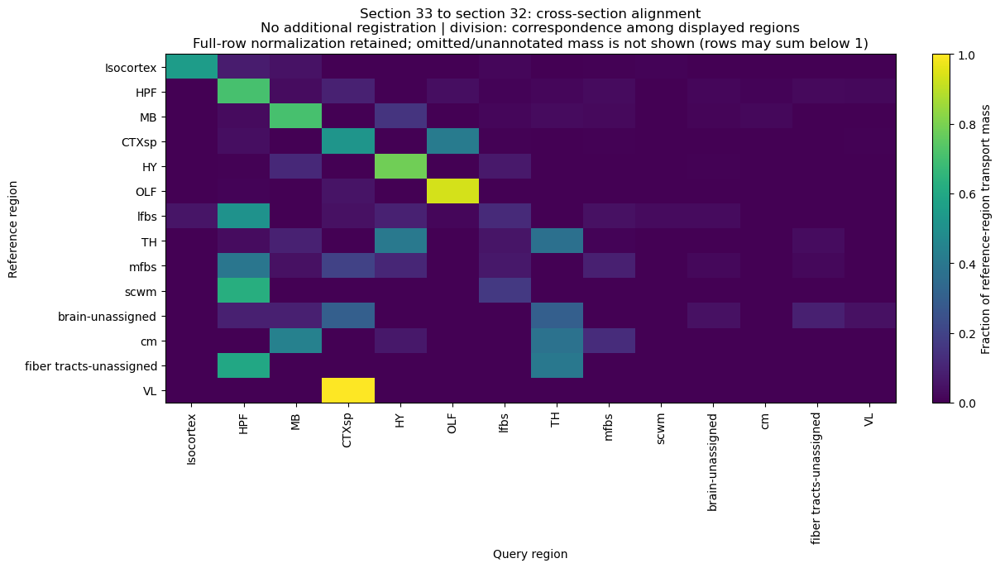

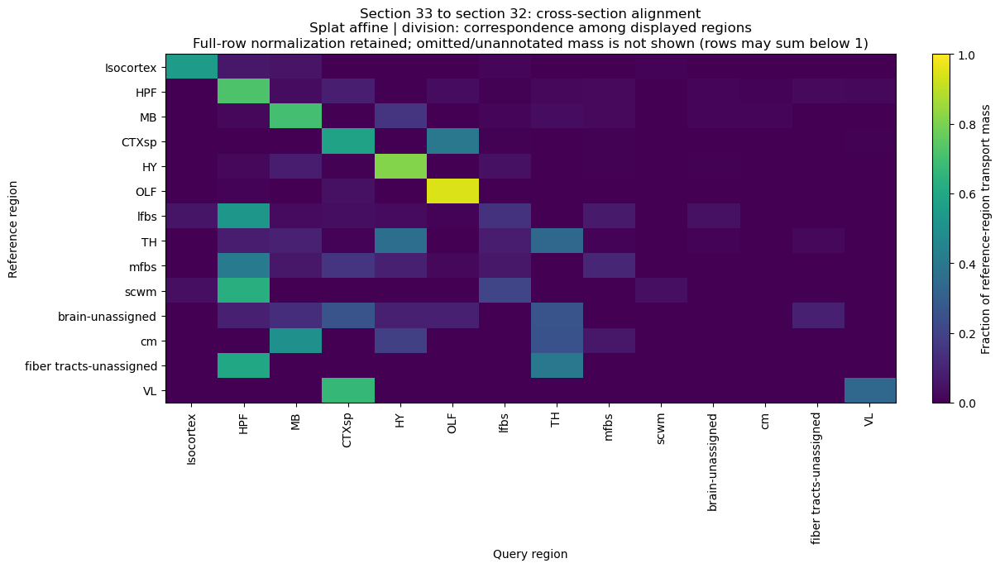

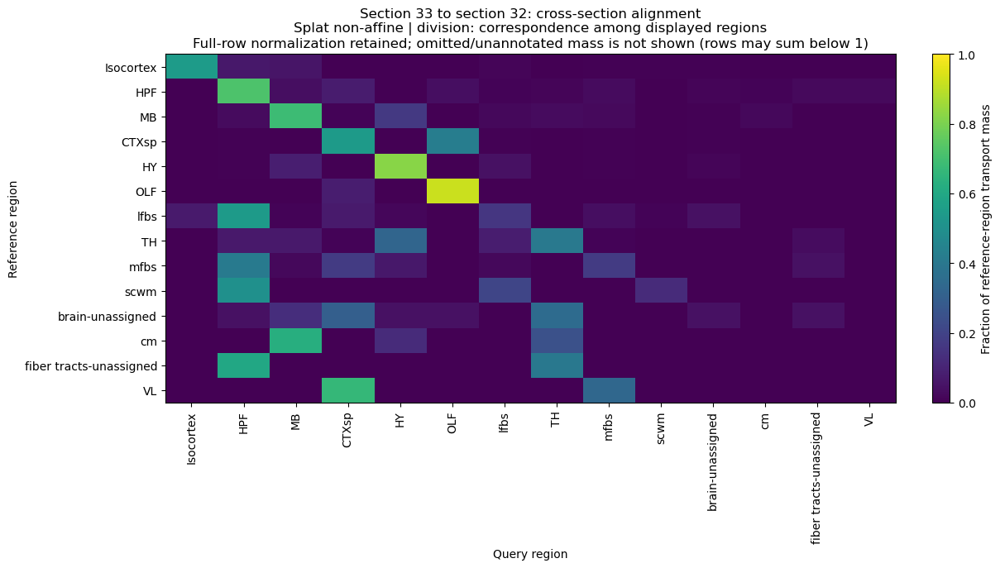

In [8]:
import importlib
import paper.allen_ccf_diagnostics as ccf_diagnostics
importlib.reload(ccf_diagnostics)

CCF_CONDITIONS = ('natural',)
CONFUSION_METHODS = ['Unregistered', 'Splat affine', 'Splat non-affine']
MAXIMUM_DISPLAY_REGIONS = 20
if 'cases' not in globals() or not cases or any(c['role'] != PHASE for c in cases):
    raise RuntimeError('Load the completed case mappings for this phase first.')
ccf_cases = [c for c in cases if c['evaluation']['condition'] in CCF_CONDITIONS]
if not ccf_cases: raise ValueError('No matching CCF diagnostic cases')
if not set(CONFUSION_METHODS).issubset(METHOD_ORDER): raise ValueError('Unknown confusion-plot method')
ccf_hierarchy = ccf_diagnostics.load_hierarchy()
ccf_summary, ccf_regions, ccf_confusion = ccf_diagnostics.analyze_cases(
    ccf_cases, ccf_hierarchy, OUTPUT/'ccf_diagnostics'/PHASE, METHOD_ORDER)
ccf_display = ccf_summary.copy()
ccf_display['case'] = ccf_display['case'].map(case_title)
ccf_display['method'] = ccf_display['method'].map(method_label)
display(ccf_display.rename(columns={
    'case':'Experiment','method':'Method','level':'Atlas level',
    'matching_mass':'Matching mass (fraction)','scored_mass':'Annotated-pair mass (fraction)',
    'agreement_given_scored':'Agreement within annotated pairs',
    'marginal_label_ceiling':'Region-proportion ceiling',
    'reference_unannotated_mass':'Reference unannotated mass',
    'query_unannotated_mass':'Query unannotated mass'}))
ccf_figures = ccf_diagnostics.diagnostic_figures(
    ccf_summary, ccf_regions, ccf_confusion, METHOD_ORDER,
    maximum_regions=MAXIMUM_DISPLAY_REGIONS, confusion_methods=CONFUSION_METHODS,
    hierarchy=ccf_hierarchy)
for name, fig in ccf_figures.items():
    export(fig, name)
    plt.close(fig)


## Freeze development before evaluation

Freeze only after reviewing the development pair and settling settings. Setting
FREEZE_DEVELOPMENT=True records the configuration, package versions, code signature,
and complete development results. To evaluate, change PHASE to evaluation and leave
FREEZE_DEVELOPMENT=False. Do not retune on the evaluation results. If settings need
revision afterward, report the analysis as exploratory rather than a frozen test.

A successful proof of concept need not beat every baseline. Report recovery where
known, anatomy/coverage on natural pairs, failure cases, and the fact that atlas
labels and prealigned coordinates limit independent anatomical validation.

In [9]:
expected=len(selected)*len(CONDITIONS)*len(METHOD_ORDER)
if len(metrics)!=expected: raise RuntimeError('Incomplete method/condition matrix; cannot freeze')
if FREEZE_DEVELOPMENT:
    if PHASE!='development': raise RuntimeError('Freeze only in development')
    if MANIFEST.exists() and json.loads(MANIFEST.read_text())['protocol_id']!=ID:
        raise RuntimeError('A different protocol is already frozen; preserve it and explicitly plan a new experiment')
    MANIFEST.write_text(json.dumps(dict(protocol_id=ID,config=CONFIG,
        development_results=str(OUTPUT/'development_registration_metrics.csv'),
        development_results_sha256=hashlib.sha256((OUTPUT/'development_registration_metrics.csv').read_bytes()).hexdigest()),indent=2))
    print('Development protocol frozen. Evaluation can now be enabled.')
else:
    print('No protocol changes. Review results before freezing development.')


No protocol changes. Review results before freezing development.


## Central registration figure

One nine-panel figure separates cross-section alignment from known-transform
recovery. The fixed visual example is the first predefined evaluation pair, 28/29,
not the best-scoring pair. The displayed model is splat affine in every column.
The quantitative panels retain both evaluation pairs and every comparison method,
including splat non-affine. No new model selection is performed.

**A and D: natural cross-section alignment.** Section 29 mapped into section 28's
frame, before additional registration (A) and after splat affine registration (D).
The released coordinates are already approximately aligned; gains may be subtle.

**B and E: rigid recovery.** A rotated/translated copy of section 28, before (B)
and after splat affine (E). Reference and query have identical expression and
measurement identities. This is an optimistic controlled recovery task.

**C and F: smooth recovery.** The same reference section with rotation, translation
and additional sinusoidal displacement, before (C) and after splat affine (F).
This is a nonrigid imposed distortion, but much of it may be approximated by affine
registration. It does not demonstrate that non-affine splats outperform affine.

All six overlays share coordinate limits and use the same atlas-division palette.
Filled circles are reference measurements; larger hollow circles are query measurements. Coarse colors
show broad anatomical correspondence, not exact-parcellation agreement. Atlas labels
are evaluation-only and are not independent manual annotations.

**G: cross-section expression agreement.** Each method has two points, one per
evaluation pair. The metric is symmetric, coverage-weighted observed-expression
cosine; unsupported measurements contribute zero. Gray ticks show each method's
geometry-matched shuffled-expression mean. Higher is better. This axis is zoomed
to the observed range and is not a zero-origin bar chart. Expression also informs
registration, so this is a consistency metric, not independent validation.

**H and I: rigid and smooth positional recovery.** Median positional error in units
of median reference measurement spacing. Both evaluation sections are shown; lower
is better. These panels share a hybrid linear/logarithmic axis so near-zero errors
and failures are visible. Point symbols identify pairs, not uncertainty estimates.

The figure supports a limited proof-of-concept claim: splat-based registration is
competitive on these evaluated sections, not uniformly superior. Confusion matrices,
CCF hierarchy diagnostics and reconstruction checks remain supporting analyses.

Run this section after loading the evaluation case mappings and computing their
cosine scores. It reads completed tables and mappings only; no fitting or rescoring.
The PNG/PDF export is named `registration_central_figure`.

/home/javeda/miniconda3/envs/spatsplat/lib/python3.11/site-packages/abc_atlas_access/abc_atlas_cache/cloud_cache.py:679: OutdatedManifestWarning: You are loading releases/20260415/manifest.json. A more up to date version of the dataset -- releases/20261031/manifest.json -- exists online. To see the changes between the two versions of the dataset, run
type.compare_manifests('releases/20260415/manifest.json', 'releases/20261031/manifest.json')
To load another version of the dataset, run
type.load_manifest('releases/20261031/manifest.json')
  warnings.warn(msg, OutdatedManifestWarning)


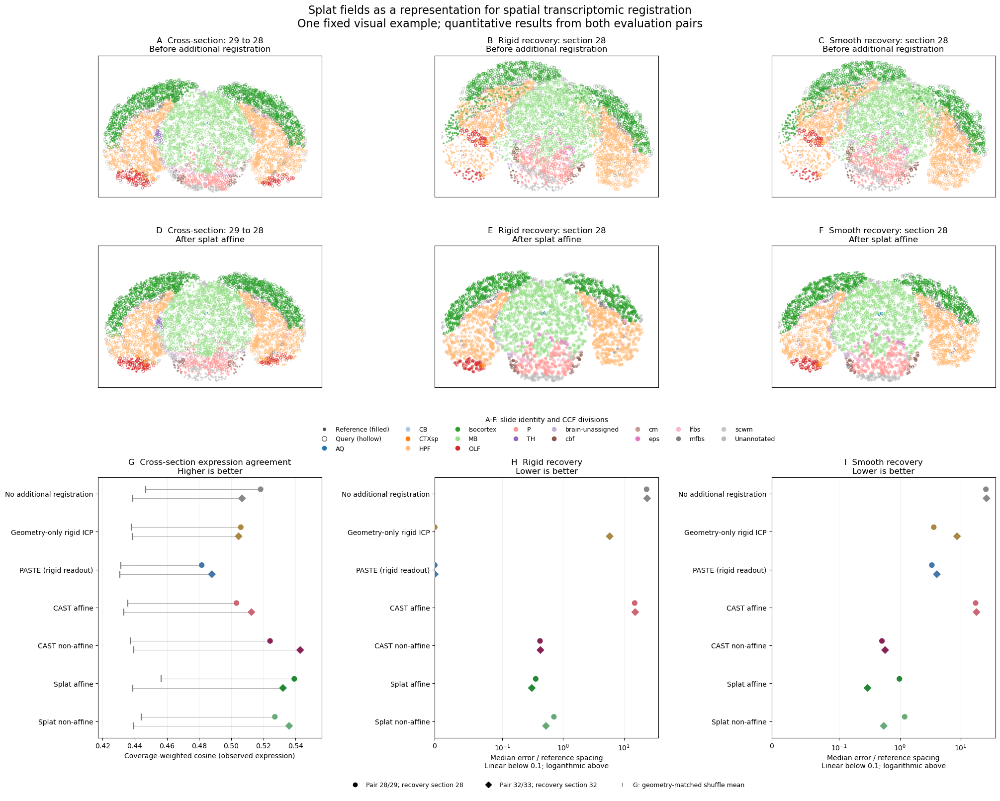

876

In [10]:
import importlib
import paper.allen_registration_figure as central_registration
importlib.reload(central_registration)

if PHASE != 'evaluation':
    raise RuntimeError('Use the completed evaluation phase for the central figure.')
if 'cases' not in globals() or not cases or any(c['role'] != 'evaluation' for c in cases):
    raise RuntimeError('Load the completed evaluation case mappings first.')
central_registration_path = OUTPUT/'evaluation_registration_metrics.csv'
central_cosine_path = OUTPUT/f'evaluation_expression_cosine_k5_p99_seed{SEED}.csv'
for path in (central_registration_path, central_cosine_path):
    if not path.exists(): raise FileNotFoundError(f'Complete the evaluation analysis first: {path}')
from paper.allen_ccf_diagnostics import load_hierarchy
central_hierarchy = load_hierarchy()
central_metrics = pd.read_csv(central_registration_path)
central_cosine = pd.read_csv(central_cosine_path)
central_fig = central_registration.central_figure(
    cases, central_metrics, central_cosine, central_hierarchy, METHOD_ORDER,
    example=(28,29), pairs=((28,29),(32,33)))
export(central_fig, 'registration_central_figure')
plt.close(central_fig)
(OUTPUT/'registration_central_figure_sources.json').write_text(json.dumps(dict(
    visual_example=[28,29],visual_method='Splat affine',evaluation_pairs=[[28,29],[32,33]],
    methods=METHOD_ORDER,registration_table=str(central_registration_path),
    cosine_table=str(central_cosine_path),
    registration_sha256=hashlib.sha256(central_registration_path.read_bytes()).hexdigest(),
    cosine_sha256=hashlib.sha256(central_cosine_path.read_bytes()).hexdigest()),indent=2))


## Alternative compact registration figure
This separate six-panel figure leaves the original central figure unchanged. Run the central-figure setup cell above first. No fitting or rescoring is performed.

**A/B:** section 29 mapped to 28, before registration and after splat affine. **D/E:** the same comparison for section 33 mapped to 32. Filled reference and hollow query markers share CCF division colors; limits match within each pair.

**C:** coverage-weighted observed-expression cosine for every method on both natural pairs (higher is better). **F:** median known-position recovery error in reference-spacing units, with filled markers for rigid and hollow markers for smooth distortion (lower is better). Circles and diamonds distinguish pairs in C/F. F uses a linear scale below 0.1 and logarithmic above. Each point represents one pair, not an uncertainty estimate. Non-affine methods remain in the quantitative comparisons.


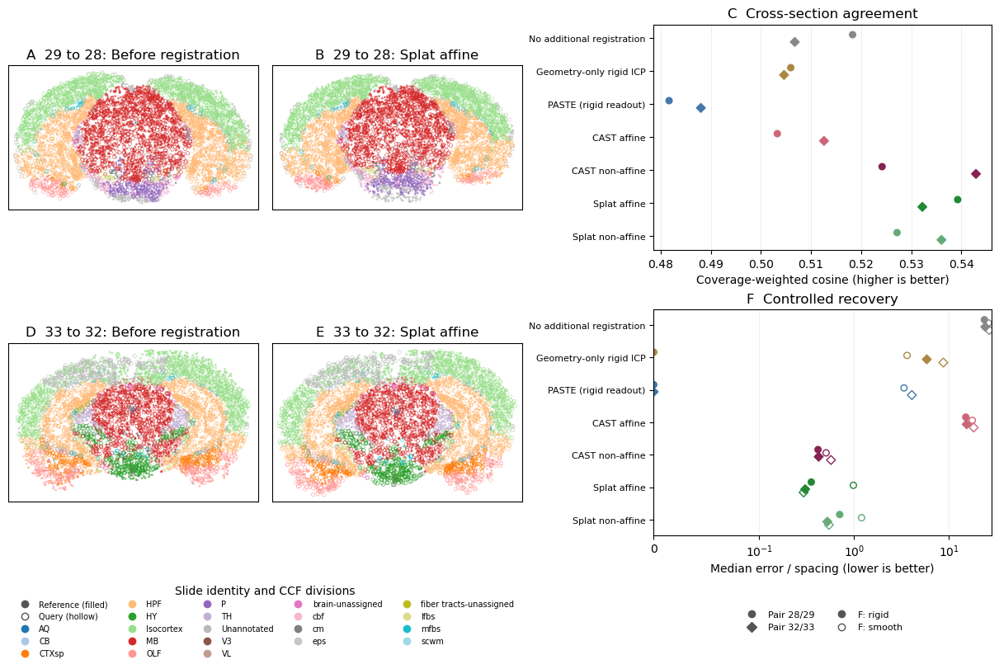

In [11]:
importlib.reload(central_registration)
compact_registration_fig = central_registration.compact_figure(
    cases, central_metrics, central_cosine, central_hierarchy, METHOD_ORDER,
    pairs=((28,29),(32,33)))
export(compact_registration_fig, 'registration_compact_figure')
plt.close(compact_registration_fig)


## Alternative twelve-panel registration overlays
Columns show natural cross-section registration, same-section rigid recovery, and same-section smooth recovery. Rows A-C/D-F show pair 28/29 before/after splat affine; rows G-I/J-L show pair 32/33 before/after. Synthetic recovery uses a distorted copy of section 28 or 32, not its adjacent section. Limits match across all six panels for each pair. Colors identify CCF divisions, with filled reference and hollow query markers. Natural sections are already approximately aligned, so small visible changes are expected; the controlled distortions test a different, known-position recovery task.
**M (upper right):** coverage-weighted observed-expression cosine for all methods and both natural pairs, higher is better. Circles represent 29 to 28; diamonds represent 33 to 32. **N (lower right):** median known-position recovery error in reference-spacing units, lower is better. Here circles represent distorted copies of section 28 and diamonds represent distorted copies of section 32, not adjacent-section pairs. Filled/hollow markers identify rigid/smooth distortions. Points are individual case results, not uncertainty estimates. The comparison panels span two overlay rows each. Run the central-figure setup cell first; no fitting or rescoring is performed.


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


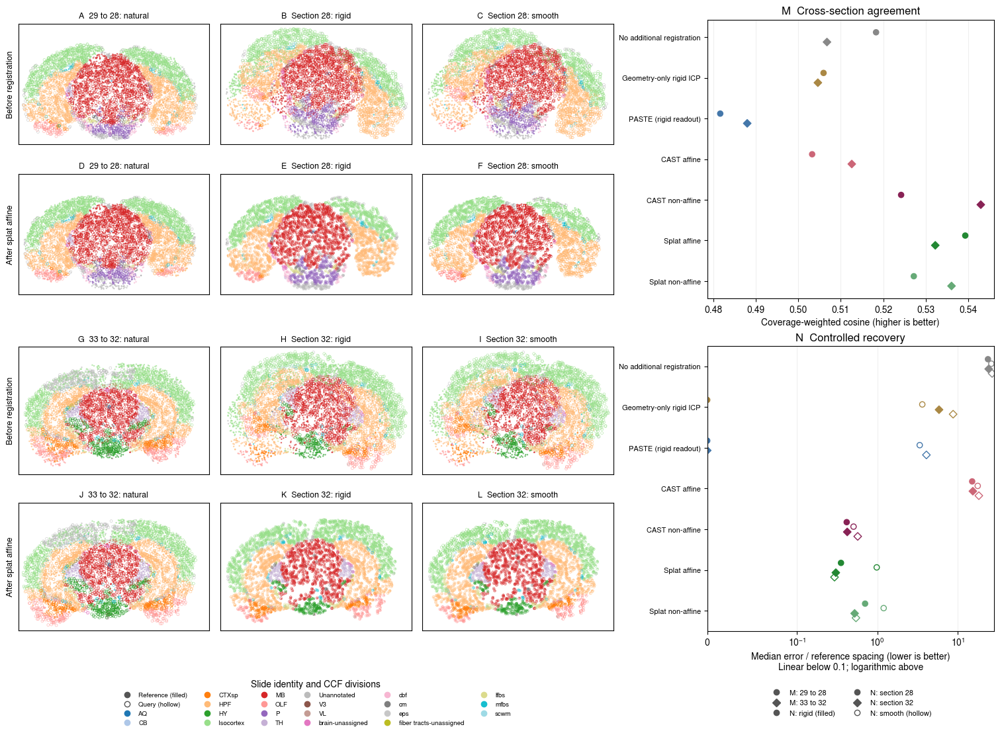

In [12]:
importlib.reload(central_registration)
all_registration_overlays = central_registration.all_overlay_figure(
    cases, central_hierarchy, central_metrics, central_cosine, METHOD_ORDER,
    pairs=((28,29),(32,33)))
with plt.rc_context(central_registration.HELVETICA_STYLE):
    export(all_registration_overlays, 'registration_twelve_overlays')
plt.close(all_registration_overlays)
